# Metrics Pipeline

Plots the per-call benchmark metrics: validity, refusals, consistency, duplicates, factuality, diversity, parity, popularity, bias_location, connectedness and similarity.

Everything is computed by `scripts/run_all.py` (see `code/README.md`); this notebook only reads `results/pipeline/calls.csv` and the Sankey flow tables, and plots.


In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

sys.path.insert(0, '../../..')
%reload_ext autoreload
%autoreload 2

from libs.visuals.vis import sns_paper_style
from libs.visuals.grouped_metrics import plot_grouped_metrics
from libs.visuals.grouped_metrics import plot_grouped_metrics_labeled
from libs.visuals.quadrant_scatter import plot_quadrant_scatter
from libs.visuals.sankey import plot_sankey, collapse_tail, normalize_by_source

from libs.metrics.aggregators import aggregate_scores
from libs.metrics.constants import *
from libs.metrics.constants import LOCATION_ORDER as LOCATION_ISO_ORDER
from libs.visuals.constants import *
from libs.utils import ios
from libs.utils.config import get_results_path


In [2]:
# Cascade: factuality_name (the name exists in Semantic Scholar) is a metric of
# its own, and factuality_author means name + field + seniority. Added in place,
# so every helper that reads these lists and dicts picks it up.
for metric_list in (ALL_METRICS, PLOT_METRICS, PLOT_TECHNICAL_METRICS):
    if 'factuality_name' not in metric_list:
        metric_list.insert(metric_list.index('factuality_author'), 'factuality_name')
PLOT_LABELS['factuality_name'] = 'Fact. $_{name}$'
METRIC_DIRECTIONS['factuality_name'] = '↑'
METRICS_NAME_MAP['factuality_name'] = 'Name factuality'
print('technical metrics:', PLOT_TECHNICAL_METRICS)

technical metrics: ['validity', 'refusals', 'consistency', 'duplicates', 'factuality_name', 'factuality_author', 'factuality_field', 'factuality_seniority']


In [3]:
RESULTS = get_results_path()
DATA = RESULTS.parent / 'data'

VALID_CALLS_PATH = RESULTS / 'pipeline/calls.csv'
PLOTS_DIR = RESULTS / 'plots'
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

CONTEXT_PROMPT_METADATA_FN = DATA / 'context/english/input.json'
MODELS_METADATA_FN = DATA / 'models/metadata.json'
MODELS_FN = DATA / 'models/models.txt'

MODELS = ios.read_list_from_file(MODELS_FN)
models_metadata = ios.load_json(MODELS_METADATA_FN)
field_metadata = ios.load_json(CONTEXT_PROMPT_METADATA_FN)
SUBFIELD_ORDER = [sf for f in FIELD_ORDER for fobj in field_metadata['fields'] if fobj['field']==f for sf in fobj['subfields']]

FIG_WIDTH = FIG_WIDTH_PAPER
FIG_HEIGHT = FIG_HEIGHT_PAPER
FIG_SIZE = (FIG_WIDTH, FIG_HEIGHT)


# Plots

In [4]:
df_valid_calls = pd.read_csv(VALID_CALLS_PATH, index_col=False)

def _pct_tier_last(c):
    parts = c.split('_')
    if c.startswith('pct_') and len(parts) == 3 and parts[1] in ('low', 'med', 'high'):
        return f"{parts[0]}_{parts[2]}_{parts[1]}"
    return c
df_valid_calls = df_valid_calls.rename(columns=_pct_tier_last)

# Idempotent: factuality_location -> bias_location (issue #36). CSVs built before
# the rename still carry the old column name; ones built after are left untouched.
df_valid_calls = df_valid_calls.rename(columns=METRIC_RENAME_MAP)

print(f'Loaded {len(df_valid_calls):,} rows × {len(df_valid_calls.columns)} columns from {VALID_CALLS_PATH}')

Loaded 928,800 rows × 62 columns from /code/asanchez/LLMScholar-Personas/results/pipeline/calls.csv


In [5]:
df_valid_calls.head(2)

,model,created_at,run_id,language,location,role,task,target,k,field,subfield,validity,refusals,duplicates,n_total_recommendations,n_unique_authors,n_runs,consistency,factuality_name,factuality_author,...,similarity,n_used_similarity,n_excluded_similarity,connectedness,n_used_connectedness,n_excluded_connectedness,duplicates_c,refusals_c,language_en,location_en,field_en,subfield_en,task_en,target_en,role_en,model_size,model_access,model_class,model_family,model_short_name
0,deepseek-r1-32b-qwen-distill-q4_K_M,2025-10-31T20:59:40.596685171Z,1,english,Germany,Director/Recruiter,seeking potential hires,Junior Professor,10,Mathematics,Number theory,0,1,NaN,0,0,7.0000,0.0000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,English,Germany,Mathematics,Number theory,seeking potential hires,Junior Professor,Director/Recruiter,M,open-weight,True,deepseek,deepseek-r1-32
1,deepseek-r1-32b-qwen-distill-q4_K_M,2025-10-31T20:59:41.677128784Z,1,english,South Africa,Director/Recruiter,seeking potential hires,Junior Professor,10,Physics,Condensed Matter,0,0,NaN,0,0,8.0000,0.0000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,English,South Africa,Physics,Condensed Matter,seeking potential hires,Junior Professor,Director/Recruiter,M,open-weight,True,deepseek,deepseek-r1-32


In [6]:
sns_paper_style(font_scale=1.55)

In [7]:

PLOTS_DIR.mkdir(parents=True, exist_ok=True)
_removed = 0
for _old in PLOTS_DIR.glob('*.pdf'):
    _old.unlink()
    _removed += 1
print(f'Cleared {PLOTS_DIR} — {_removed} stale PDF(s) removed')

Cleared /code/asanchez/LLMScholar-Personas/results/plots — 62 stale PDF(s) removed


## RQ1 & RQ2

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_stacked.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_stacked.pdf


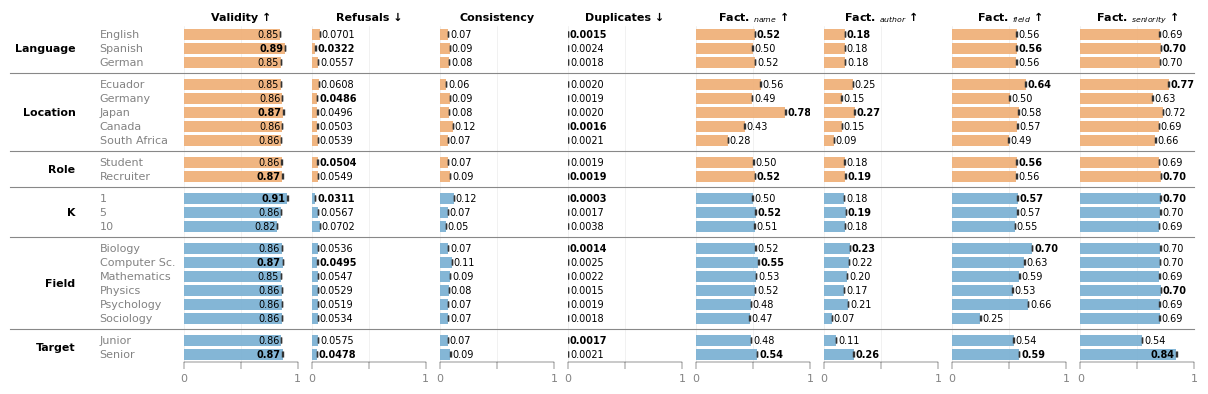

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_stacked.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_stacked.pdf


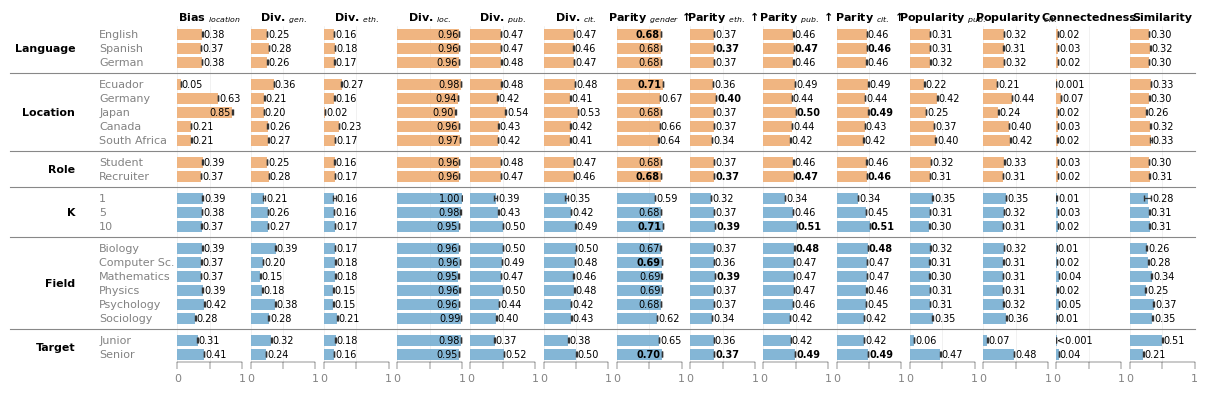

In [8]:
variables = {'persona': PERSONA_VARIABLES, 'context': MAIN_CONTEXT_VARIABLES}

df_metric = pd.DataFrame()
group_configs = []
for i, (prompt_var_class, vars) in enumerate(variables.items()):
    for j, var in enumerate(vars):
        tmp = aggregate_scores(df_valid_calls, [var]).rename(columns={var: 'label'})
        tmp.loc[:,'column'] = var
        df_metric = pd.concat([df_metric, tmp], ignore_index=True)

        group_configs.append({'label': var.split("_en")[0].capitalize(), 
                              'column': 'label', 
                              'color': PROMPT_VAR_COLORS.get(prompt_var_class), 
                              'filter': {'column':var},
                              'order': ORDER_MAP[var],
                              'shade': False})
            
for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_stacked.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_metric,
        group_configs=group_configs,
        row_labels = SENIORITY_MAP | ROLE_MAP | {'Computer Science':'Computer Sc.'},
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * len(group_configs)/1.1),
        textwrap_width = 20,
        section_style='plain',
        section_label_pad=0.2,
        section_label_align='right',
        row_label_align='left',
        section_label_width=0.5,
        row_label_width=1.9,
        row_label_pad=0.3,
        section_sep_left_pad=-0.22
    )


## RQ3: Insfrastructure

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_infrastructure_technical.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_infrastructure_technical.pdf


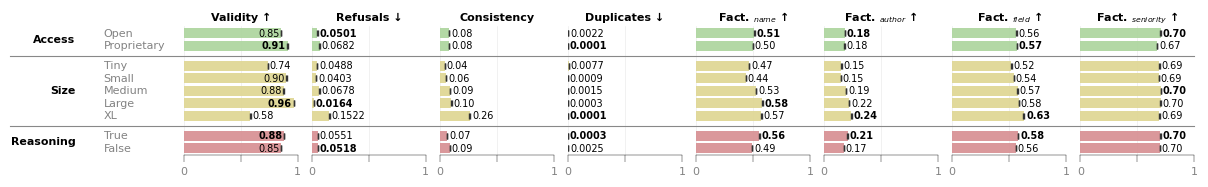

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_infrastructure_social.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_infrastructure_social.pdf


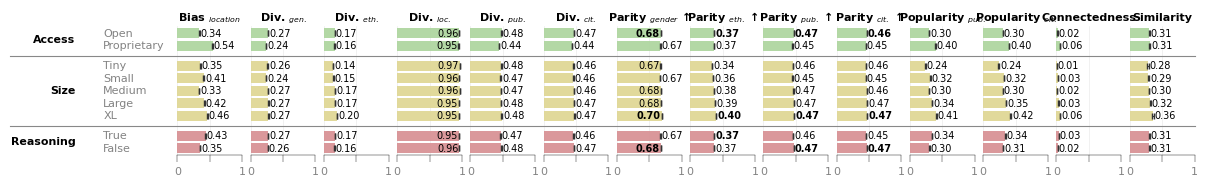

In [9]:

df_infra = pd.DataFrame()
for c in ['model_access','model_size','model_class']:
    tmp = aggregate_scores(df_valid_calls, [c]).rename(columns={c: 'label'})
    tmp.loc[:,'column'] = c
    df_infra = pd.concat([df_infra, tmp], ignore_index=True)

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_infrastructure_{metric_type}.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_infra,
        group_configs=[
            {'label': MODEL_ARCHITECTURE_MAP['model_access'], 'column': 'label', 'filter': {'column': 'model_access'}, 'color': "#ADD59E", 'order': ACCESS_ORDER, 'shade': False},
            {'label': MODEL_ARCHITECTURE_MAP['model_size'],   'column': 'label', 'filter': {'column': 'model_size'},   'color': "#DFD693", 'order': SIZE_ORDER, 'shade': False},
            {'label': MODEL_ARCHITECTURE_MAP['model_class'],  'column': 'label', 'filter': {'column': 'model_class'},  'color': "#D78F93", 'order': REASONING_ORDER, 'shade': False},
        ],
        row_labels=ACCESS_MAP | SIZE_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * 2.1),
        textwrap_width = 20,
        section_style='plain',
        section_label_pad=0.2,
        section_label_align='right',
        row_label_align='left',
        section_label_width=0.5,
        row_label_width=1.9,
        row_label_pad=0.3,
        section_sep_left_pad=-0.22
    )


## RQ4: Socio-Technical Trade-off

Scatter — 43 models
Technical max: 4.555, Social max: 2.070


Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_vs_social.pdf


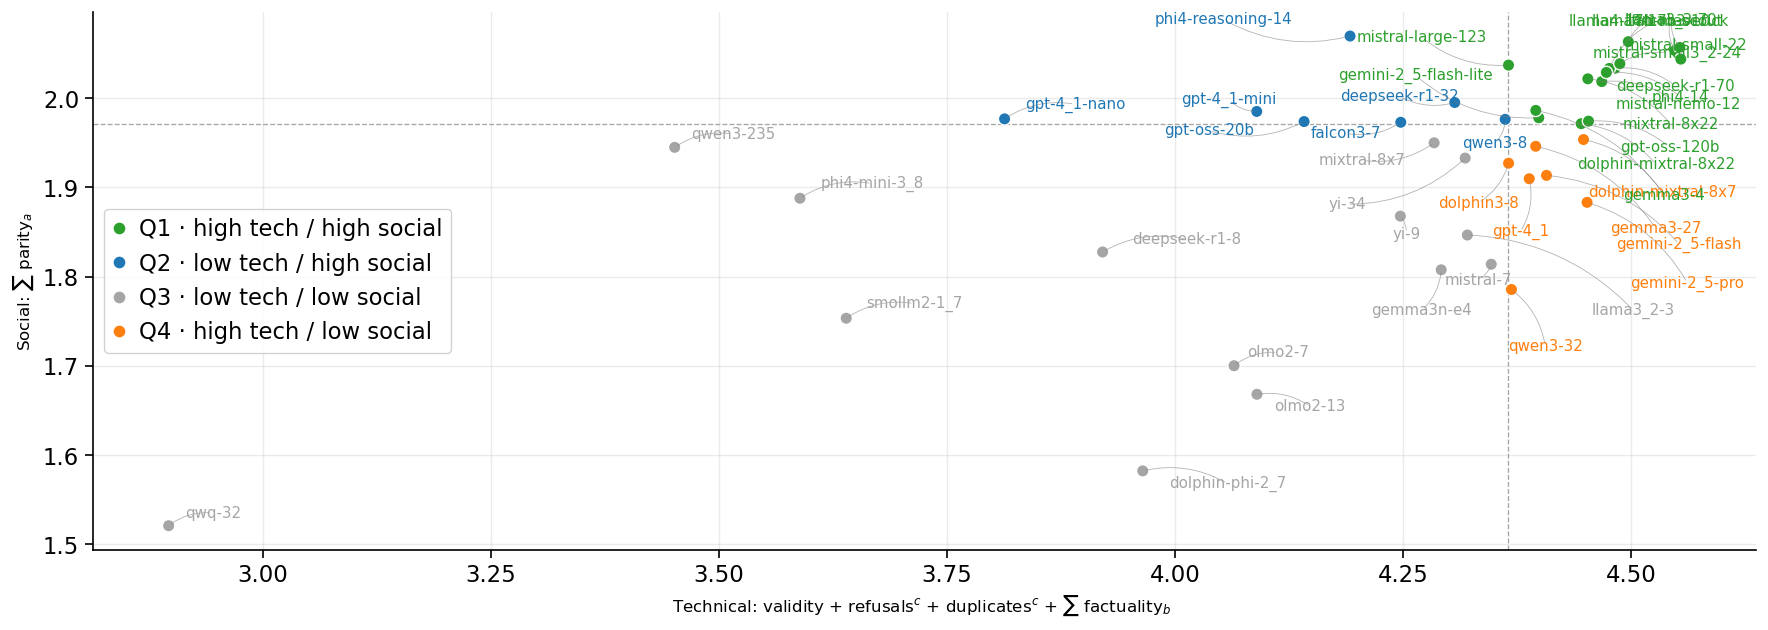

In [10]:

df_data_tmp = df_valid_calls.copy()

agg_cols = TECHNICAL_METRICS_NORM + PARITY_METRICS

df_data_tmp.loc[:, 'color'] = df_data_tmp.loc[:,'model_family'].apply(lambda fam: MODEL_FAMILY_COLORS.get(fam, '#6B7280'))

per_model_mean = (df_data_tmp.groupby(['model_short_name','model_family', 'color'], dropna=False, observed=True)[agg_cols]
                  .mean()
                  .reset_index())
per_model_std = (df_data_tmp.groupby(['model_short_name','model_family', 'color'], dropna=False, observed=True)[agg_cols]
                  .std()
                  .reset_index())

per_model_mean['x_technical'] = per_model_mean[TECHNICAL_METRICS_NORM].sum(axis=1, skipna=False)
per_model_mean['y_social']    = per_model_mean[PARITY_METRICS].sum(axis=1, skipna=False)

per_model_std['x_technical'] = per_model_std[TECHNICAL_METRICS_NORM].sum(axis=1, skipna=False)
per_model_std['y_social']    = per_model_std[PARITY_METRICS].sum(axis=1, skipna=False)

print(f'Scatter — {per_model_mean.model_short_name.nunique()} models')
print(f"Technical max: {per_model_mean['x_technical'].max():.3f}, Social max: {per_model_mean['y_social'].max():.3f}")

fig, ax = plot_quadrant_scatter(per_model_mean, label_col="model_short_name", figsize=(FIG_WIDTH, 5.5), show_quadrant_legend=True)

fn = str(PLOTS_DIR / f'plot_technical_vs_social.pdf')
plt.savefig(fn, bbox_inches='tight', dpi=FIG_DPI)
print(fn)

plt.show()
plt.close()


# Additional

___


## K

,k,n,validity_mean,validity_ci,validity_std,refusals_mean,refusals_ci,refusals_std,connectedness_mean,connectedness_ci,connectedness_std,similarity_mean,similarity_ci,similarity_std,consistency_mean,consistency_ci,consistency_std,duplicates_mean,duplicates_ci,duplicates_std,...,pct_works_med_ci,pct_works_med_std,pct_works_high_mean,pct_works_high_ci,pct_works_high_std,pct_citations_low_mean,pct_citations_low_ci,pct_citations_low_std,pct_citations_med_mean,pct_citations_med_ci,pct_citations_med_std,pct_citations_high_mean,pct_citations_high_ci,pct_citations_high_std,popularity_works_mean,popularity_works_ci,popularity_works_std,popularity_citations_mean,popularity_citations_ci,popularity_citations_std
0,1,309600,0.9096,0.0010,0.2868,0.0311,0.0006,0.1735,0.0075,0.0065,0.0862,0.2775,0.0549,0.7234,0.1230,0.0008,0.2221,0.0003,0.0001,0.0142,...,0.0043,0.4457,0.3512,0.0046,0.4758,0.3328,0.0046,0.4695,0.3135,0.0045,0.4622,0.3537,0.0046,0.4767,0.3512,0.0046,0.4758,0.3537,0.0046,0.4767
1,5,309600,0.8560,0.0012,0.3511,0.0567,0.0008,0.2313,0.0267,0.0012,0.1386,0.3053,0.0053,0.6206,0.0690,0.0005,0.1244,0.0017,0.0001,0.0341,...,0.0023,0.3833,0.3145,0.0025,0.4035,0.3740,0.0026,0.4277,0.3082,0.0024,0.3871,0.3178,0.0025,0.4064,0.3145,0.0025,0.4035,0.3178,0.0025,0.4064
2,10,309600,0.8199,0.0014,0.3843,0.0702,0.0009,0.2555,0.0225,0.0007,0.1074,0.3074,0.0037,0.5434,0.0536,0.0004,0.0978,0.0038,0.0002,0.0458,...,0.0019,0.3439,0.3012,0.0021,0.3676,0.3831,0.0022,0.4006,0.3097,0.0020,0.3486,0.3072,0.0021,0.3734,0.3012,0.0021,0.3676,0.3072,0.0021,0.3734


technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_k.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_k.pdf


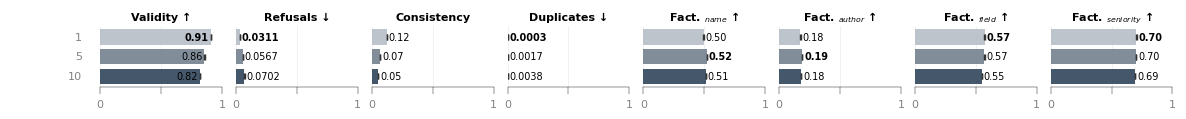

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_k.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_k.pdf


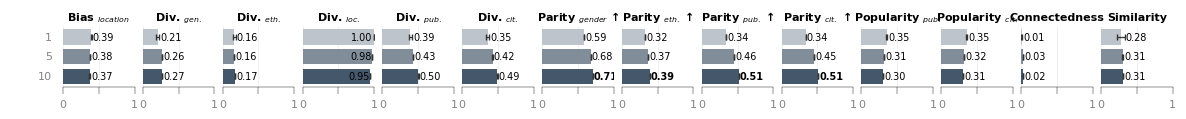

In [11]:
df_k = aggregate_scores(df_valid_calls, ['k'])
display(df_k)

for metric_type, metric_list in METRIC_TYPES.items():

    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_k.pdf')
    print(fn)
    plot_grouped_metrics(
        df_k,
        group_configs=[
            {'label': 'Top-k', 'column': 'k', 'color': '#34495E', 'order': K_ORDER},
        ],
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=FIG_SIZE
    )

### K and Language

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_k_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_k_lang.pdf


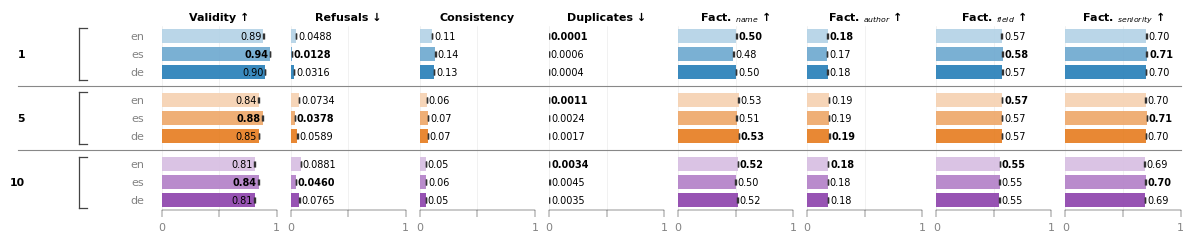

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_k_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_k_lang.pdf


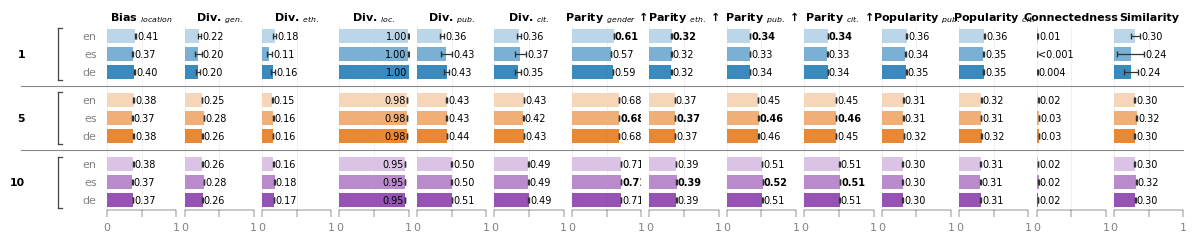

In [12]:

df_k_lang = aggregate_scores(df_valid_calls, ['k','language_en'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_k_lang.pdf')
    print(fn)
    
    plot_grouped_metrics_labeled(
        df_k_lang,
        group_configs=[
            {'label': str(k), 
             'column': 'language_en', 'color': K_COLORS[k], 'filter': {'k': k}, 'order': LANGUAGE_ORDER} for k in K_ORDER
        ],
        row_labels=LANGUAGE_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * len(LANGUAGE_ORDER))
    )


## Language

,language_en,n,validity_mean,validity_ci,validity_std,refusals_mean,refusals_ci,refusals_std,connectedness_mean,connectedness_ci,connectedness_std,similarity_mean,similarity_ci,similarity_std,consistency_mean,consistency_ci,consistency_std,duplicates_mean,duplicates_ci,duplicates_std,...,pct_works_med_ci,pct_works_med_std,pct_works_high_mean,pct_works_high_ci,pct_works_high_std,pct_citations_low_mean,pct_citations_low_ci,pct_citations_low_std,pct_citations_med_mean,pct_citations_med_ci,pct_citations_med_std,pct_citations_high_mean,pct_citations_high_ci,pct_citations_high_std,popularity_works_mean,popularity_works_ci,popularity_works_std,popularity_citations_mean,popularity_citations_ci,popularity_citations_std
0,English,309600,0.8454,0.0013,0.3615,0.0701,0.0009,0.2553,0.0223,0.0011,0.1166,0.2978,0.0054,0.5797,0.0734,0.0005,0.1489,0.0015,0.0001,0.0278,...,0.0025,0.3786,0.3142,0.0027,0.4006,0.3696,0.0028,0.4220,0.3107,0.0025,0.3832,0.3198,0.0027,0.4044,0.3142,0.0027,0.4006,0.3198,0.0027,0.4044
1,German,309600,0.8517,0.0013,0.3554,0.0557,0.0008,0.2293,0.0241,0.0011,0.1206,0.2998,0.0054,0.5760,0.0838,0.0006,0.1614,0.0018,0.0001,0.0327,...,0.0025,0.3786,0.3170,0.0027,0.4011,0.3677,0.0028,0.4228,0.3108,0.0026,0.3858,0.3215,0.0027,0.4051,0.3170,0.0027,0.4011,0.3215,0.0027,0.4051
2,Spanish,309600,0.8884,0.0011,0.3148,0.0322,0.0006,0.1765,0.0258,0.0011,0.1239,0.3202,0.0051,0.5718,0.0893,0.0006,0.1710,0.0024,0.0001,0.0388,...,0.0024,0.3724,0.3111,0.0026,0.3986,0.3779,0.0027,0.4230,0.3078,0.0024,0.3797,0.3143,0.0026,0.4020,0.3111,0.0026,0.3986,0.3143,0.0026,0.4020


technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_lang.pdf


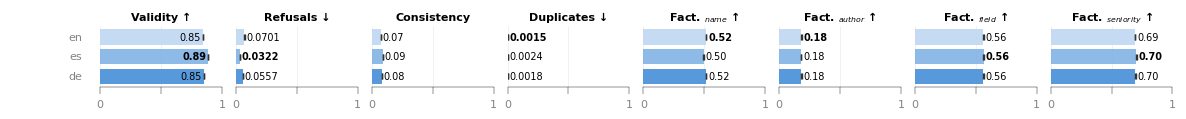

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_lang.pdf


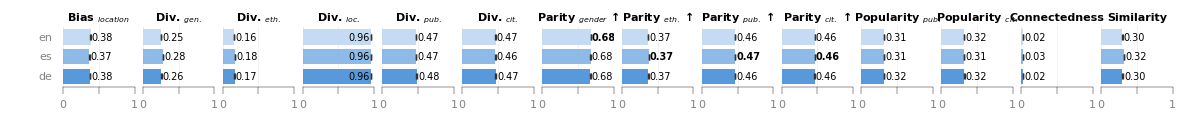

In [13]:

df_lang = aggregate_scores(df_valid_calls, ['language_en'])
display(df_lang)

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_lang.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_lang,
        group_configs=[
            {'label': 'Language', 
             'column': 'language_en', 
             'color': '#4A90D9',
             'order': LANGUAGE_ORDER},
        ],
        row_labels=LANGUAGE_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=FIG_SIZE
    )


### Language and K

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_lang_k.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_lang_k.pdf


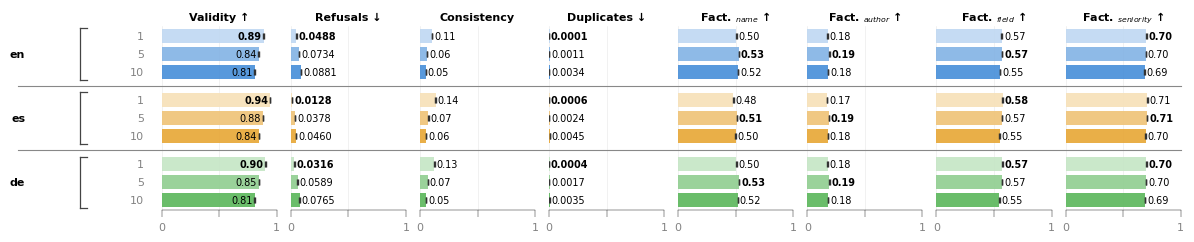

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_lang_k.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_lang_k.pdf


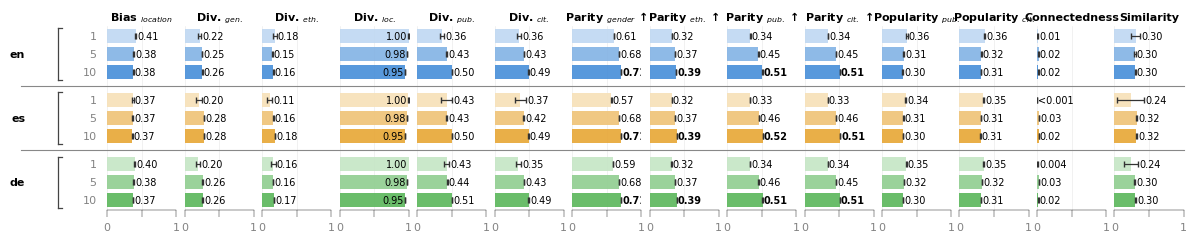

In [14]:
df_lang_k = aggregate_scores(df_valid_calls, ['language_en','k'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_lang_k.pdf')
    print(fn)
    
    plot_grouped_metrics_labeled(
        df_lang_k,
        group_configs=[
            {'label': LANGUAGE_MAP[lang], 
             'column': 'k', 
             'color': LANGUAGE_COLORS[lang],
             'filter': {'language_en': lang}, 
             'order': K_ORDER} for lang in LANGUAGE_ORDER
        ],
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * len(LANGUAGE_ORDER))
    )


### Language and Task

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_task_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_task_lang.pdf


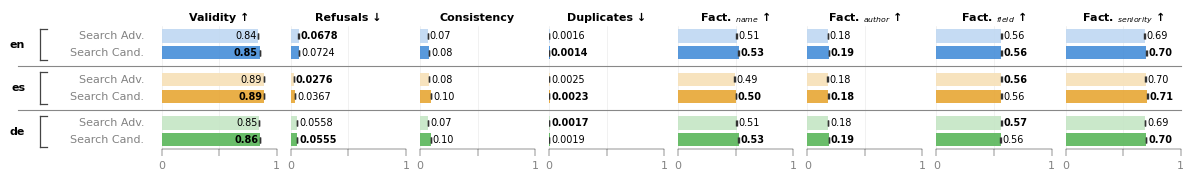

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_task_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_task_lang.pdf


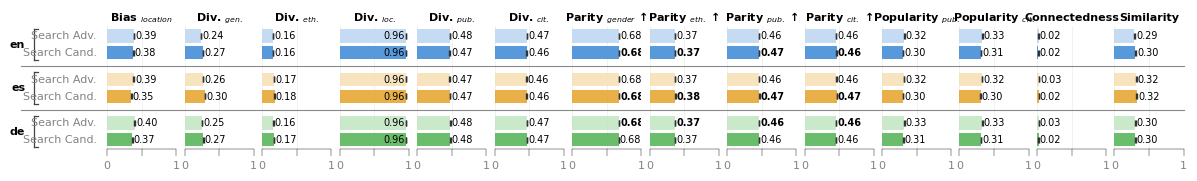

In [15]:

from pydoc import text


df_lang_task = aggregate_scores(df_valid_calls, ['language_en','task_en'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_task_lang.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_lang_task,
        group_configs=[
            {'label': LANGUAGE_MAP[language], 
             'column': 'task_en', 
             'color': LANGUAGE_COLORS[language],
             'filter': {'language_en': language}, 
             'order': TASK_ORDER}
            for language in LANGUAGE_ORDER
        ],
        row_labels=TASK_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * len(TASK_ORDER)),
        textwrap_width=25
    )


## Location

,location_en,n,validity_mean,validity_ci,validity_std,refusals_mean,refusals_ci,refusals_std,connectedness_mean,connectedness_ci,connectedness_std,similarity_mean,similarity_ci,similarity_std,consistency_mean,consistency_ci,consistency_std,duplicates_mean,duplicates_ci,duplicates_std,...,pct_works_med_ci,pct_works_med_std,pct_works_high_mean,pct_works_high_ci,pct_works_high_std,pct_citations_low_mean,pct_citations_low_ci,pct_citations_low_std,pct_citations_med_mean,pct_citations_med_ci,pct_citations_med_std,pct_citations_high_mean,pct_citations_high_ci,pct_citations_high_std,popularity_works_mean,popularity_works_ci,popularity_works_std,popularity_citations_mean,popularity_citations_ci,popularity_citations_std
0,Canada,185760,0.8634,0.0016,0.3435,0.0503,0.0010,0.2186,0.0312,0.0018,0.1366,0.3212,0.0079,0.6101,0.1152,0.0009,0.1869,0.0016,0.0001,0.0287,...,0.0034,0.3859,0.3737,0.0037,0.4261,0.2863,0.0036,0.4144,0.3167,0.0035,0.4009,0.3970,0.0038,0.4337,0.3737,0.0037,0.4261,0.3970,0.0038,0.4337
1,Ecuador,185760,0.8522,0.0016,0.3549,0.0608,0.0011,0.2390,0.0012,0.0003,0.0300,0.3298,0.0049,0.5378,0.0565,0.0006,0.1316,0.0020,0.0002,0.0373,...,0.0026,0.3698,0.2249,0.0025,0.3450,0.3934,0.0029,0.4090,0.3951,0.0027,0.3823,0.2115,0.0024,0.3367,0.2249,0.0025,0.3450,0.2115,0.0024,0.3367
2,Germany,185760,0.8638,0.0016,0.3431,0.0486,0.0010,0.2150,0.0703,0.0027,0.2059,0.3018,0.0084,0.6339,0.0860,0.0008,0.1640,0.0019,0.0002,0.0333,...,0.0032,0.3552,0.4235,0.0039,0.4368,0.3137,0.0037,0.4194,0.2416,0.0033,0.3672,0.4448,0.0039,0.4399,0.4235,0.0039,0.4368,0.4448,0.0039,0.4399
3,Japan,185760,0.8739,0.0015,0.3320,0.0496,0.0010,0.2172,0.0221,0.0011,0.1050,0.2600,0.0058,0.5523,0.0822,0.0008,0.1613,0.0020,0.0002,0.0335,...,0.0028,0.3592,0.2460,0.0027,0.3464,0.5187,0.0033,0.4108,0.2458,0.0027,0.3400,0.2354,0.0027,0.3426,0.2460,0.0027,0.3464,0.2354,0.0027,0.3426
4,South Africa,185760,0.8559,0.0016,0.3512,0.0539,0.0010,0.2259,0.0194,0.0020,0.1083,0.3321,0.0112,0.5975,0.0710,0.0007,0.1495,0.0021,0.0002,0.0342,...,0.0047,0.4187,0.4000,0.0050,0.4443,0.2566,0.0046,0.4087,0.3225,0.0047,0.4139,0.4208,0.0051,0.4480,0.4000,0.0050,0.4443,0.4208,0.0051,0.4480


technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_loc.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_loc.pdf


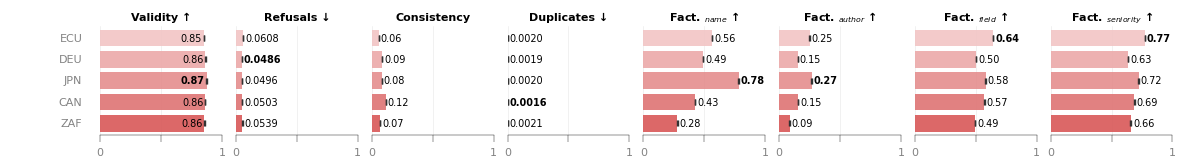

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_loc.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_loc.pdf


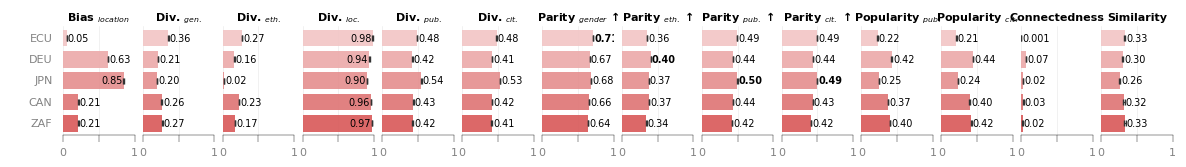

In [16]:

df_loc = aggregate_scores(df_valid_calls, ['location_en'])
display(df_loc)

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_loc.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_loc,
        group_configs=[
            {'label': 'Location', 
             'column': 'location_en', 
             'color': '#D95B5B',
             'order': LOCATION_ORDER},
        ],
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        row_labels=LOCATION_MAP,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT + (len(LOCATION_ORDER)/8))
    )


### Location and Language

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_loc_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_loc_lang.pdf


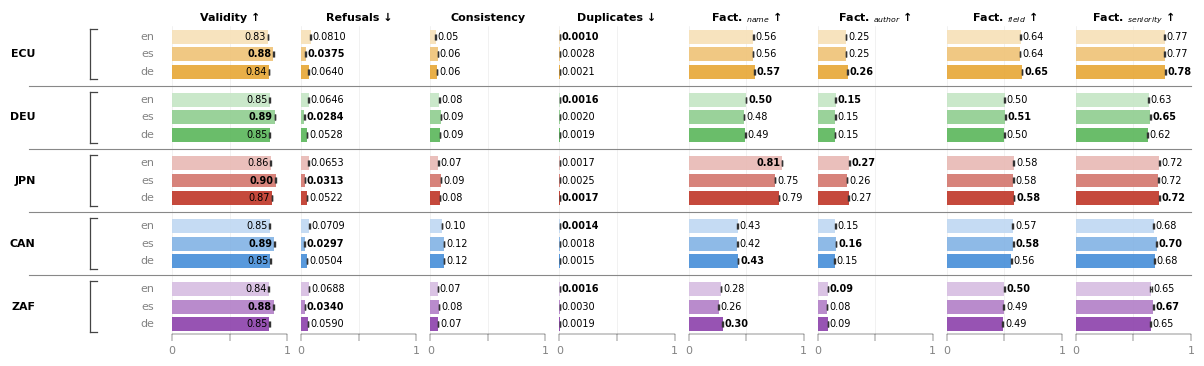

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_loc_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_loc_lang.pdf


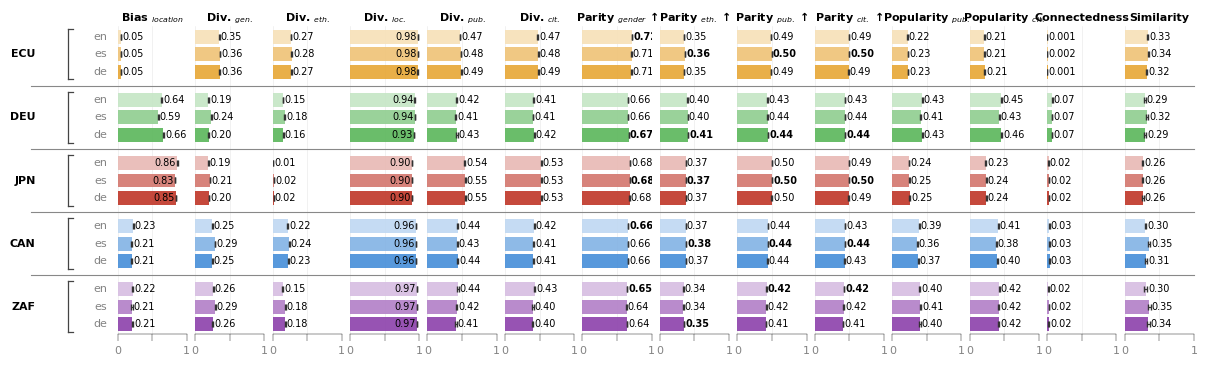

In [17]:

df_loc_lang = aggregate_scores(df_valid_calls, ['location_en','language_en'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_loc_lang.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_loc_lang,
        group_configs=[
            {'label': LOCATION_MAP[loc], 
             'column': 
             'language_en', 
             'color': LOCATION_COLORS[loc],
             'filter': {'location_en': loc}, 
             'order': LANGUAGE_ORDER} for loc in LOCATION_ORDER
        ],
        row_labels=LANGUAGE_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * len(LOCATION_ORDER))   
    );


## Task

,task_en,n,validity_mean,validity_ci,validity_std,refusals_mean,refusals_ci,refusals_std,connectedness_mean,connectedness_ci,connectedness_std,similarity_mean,similarity_ci,similarity_std,consistency_mean,consistency_ci,consistency_std,duplicates_mean,duplicates_ci,duplicates_std,...,pct_works_med_ci,pct_works_med_std,pct_works_high_mean,pct_works_high_ci,pct_works_high_std,pct_citations_low_mean,pct_citations_low_ci,pct_citations_low_std,pct_citations_med_mean,pct_citations_med_ci,pct_citations_med_std,pct_citations_high_mean,pct_citations_high_ci,pct_citations_high_std,popularity_works_mean,popularity_works_ci,popularity_works_std,popularity_citations_mean,popularity_citations_ci,popularity_citations_std
0,seeking an advisor,464400,0.8577,0.0010,0.3494,0.0504,0.0006,0.2188,0.0251,0.0009,0.1223,0.3020,0.0045,0.5807,0.0729,0.0004,0.1511,0.0019,0.0001,0.0330,...,0.0021,0.3762,0.3233,0.0022,0.4041,0.3645,0.0023,0.4208,0.3070,0.0021,0.3832,0.3285,0.0022,0.4078,0.3233,0.0022,0.4041,0.3285,0.0022,0.4078
1,seeking potential hires,464400,0.8660,0.0010,0.3407,0.0549,0.0007,0.2278,0.0232,0.0009,0.1188,0.3105,0.0042,0.5712,0.0916,0.0005,0.1697,0.0019,0.0001,0.0340,...,0.0020,0.3767,0.3053,0.0021,0.3961,0.3788,0.0022,0.4242,0.3122,0.0020,0.3825,0.3091,0.0021,0.3998,0.3053,0.0021,0.3961,0.3091,0.0021,0.3998


technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_task.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_task.pdf


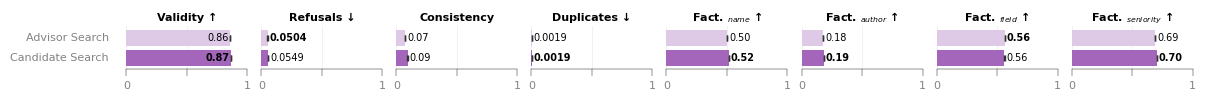

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_task.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_task.pdf


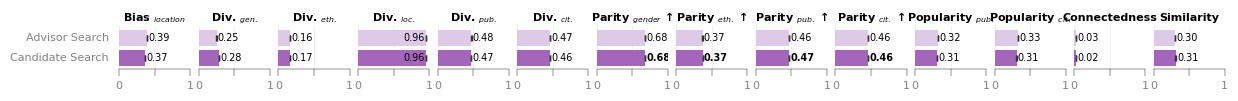

In [18]:
df_task = aggregate_scores(df_valid_calls, ['task_en'])
display(df_task)

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_task.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_task,
        group_configs=[
            {'label': 'Task', 
             'column': 'task_en', 
             'color': '#9B59B6',
             'order': TASK_ORDER},
        ],
        row_labels=TASK_MAP_LONG,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * 0.7),
        textwrap_width=20
    )


### Task and K

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_task_k.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_task_k.pdf


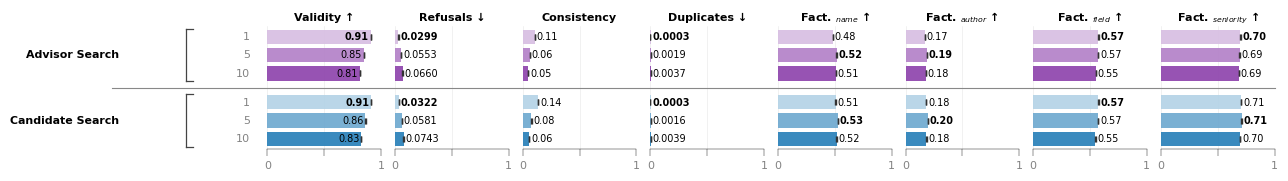

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_task_k.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_task_k.pdf


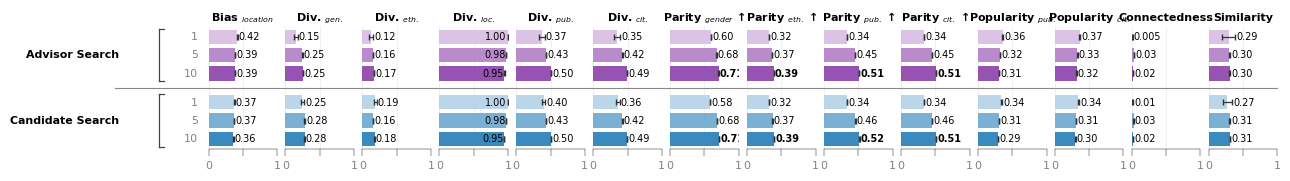

In [19]:

df_task_k = aggregate_scores(df_valid_calls, ['task_en','k'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_task_k.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_task_k,
        group_configs=[
            {'label': TASK_MAP_LONG[task_val], 
             'column': 'k', 
             'color': TASK_COLORS[task_val],
             'filter': {'task_en': task_val}, 
             'order': K_ORDER} for task_val in TASK_ORDER
        ],
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * len(TASK_ORDER)),
        textwrap_width=20
    )


## Role

,role_en,n,validity_mean,validity_ci,validity_std,refusals_mean,refusals_ci,refusals_std,connectedness_mean,connectedness_ci,connectedness_std,similarity_mean,similarity_ci,similarity_std,consistency_mean,consistency_ci,consistency_std,duplicates_mean,duplicates_ci,duplicates_std,...,pct_works_med_ci,pct_works_med_std,pct_works_high_mean,pct_works_high_ci,pct_works_high_std,pct_citations_low_mean,pct_citations_low_ci,pct_citations_low_std,pct_citations_med_mean,pct_citations_med_ci,pct_citations_med_std,pct_citations_high_mean,pct_citations_high_ci,pct_citations_high_std,popularity_works_mean,popularity_works_ci,popularity_works_std,popularity_citations_mean,popularity_citations_ci,popularity_citations_std
0,Director/Recruiter,464400,0.8660,0.0010,0.3407,0.0549,0.0007,0.2278,0.0232,0.0009,0.1188,0.3105,0.0042,0.5712,0.0916,0.0005,0.1697,0.0019,0.0001,0.0340,...,0.0020,0.3767,0.3053,0.0021,0.3961,0.3788,0.0022,0.4242,0.3122,0.0020,0.3825,0.3091,0.0021,0.3998,0.3053,0.0021,0.3961,0.3091,0.0021,0.3998
1,PhD student,464400,0.8577,0.0010,0.3494,0.0504,0.0006,0.2188,0.0251,0.0009,0.1223,0.3020,0.0045,0.5807,0.0729,0.0004,0.1511,0.0019,0.0001,0.0330,...,0.0021,0.3762,0.3233,0.0022,0.4041,0.3645,0.0023,0.4208,0.3070,0.0021,0.3832,0.3285,0.0022,0.4078,0.3233,0.0022,0.4041,0.3285,0.0022,0.4078


technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_role.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_role.pdf


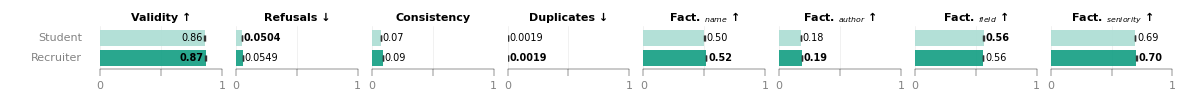

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_role.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_role.pdf


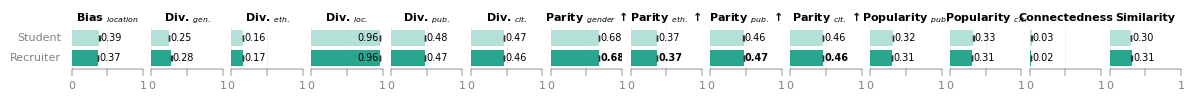

In [20]:

df_role = aggregate_scores(df_valid_calls, ['role_en'])
display(df_role)

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_role.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_role,
        group_configs=[
            {'label': 'Role', 
             'column': 'role_en', 
             'color': '#16A085',
             'order': ROLE_ORDER},
        ],
        row_labels=ROLE_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * 0.7)
    )

### Role and Language

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_role_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_role_lang.pdf


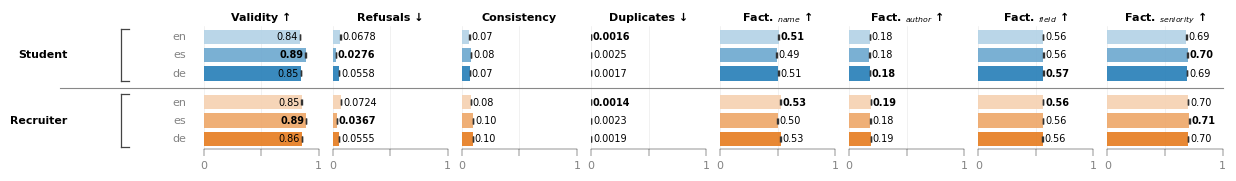

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_role_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_role_lang.pdf


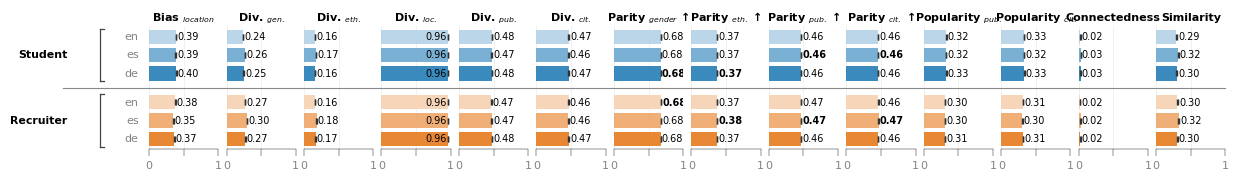

In [21]:

df_role_lang = aggregate_scores(df_valid_calls, ['role_en', 'language_en'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_role_lang.pdf')
    print(fn)
        
    plot_grouped_metrics_labeled(
        df_role_lang,
        group_configs=[
            {'label': ROLE_MAP[role_val], 
             'column': 'language_en', 
             'color': ROLE_COLORS[role_val],
             'filter': {'role_en': role_val}, 
             'order': LANGUAGE_ORDER}
            for role_val in ROLE_ORDER
        ],
        row_labels=LANGUAGE_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * len(ROLE_ORDER))
    )

## Field

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_field.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_field.pdf


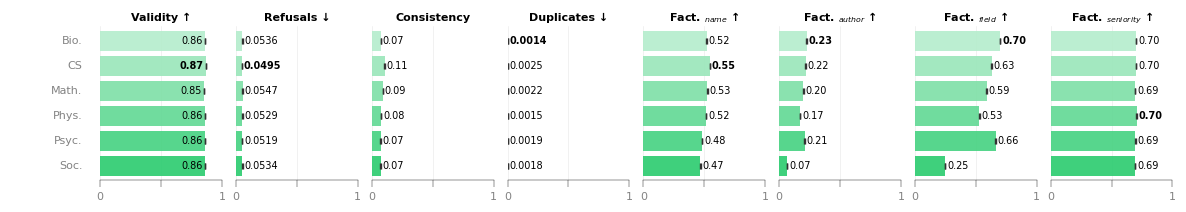

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_field.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_field.pdf


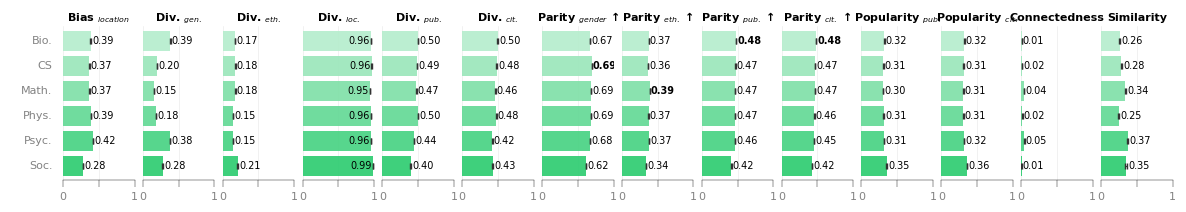

In [22]:

df_field = aggregate_scores(df_valid_calls, ['field_en'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_field.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_field,
        group_configs=[
            {'label': 'Field', 
             'column': 'field_en', 
             'color': '#2ECC71', 
             'order': FIELD_ORDER},
        ],
        row_labels=FIELD_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT + (len(FIELD_ORDER)/5))
    )


### Field and Language

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_field_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_field_lang.pdf


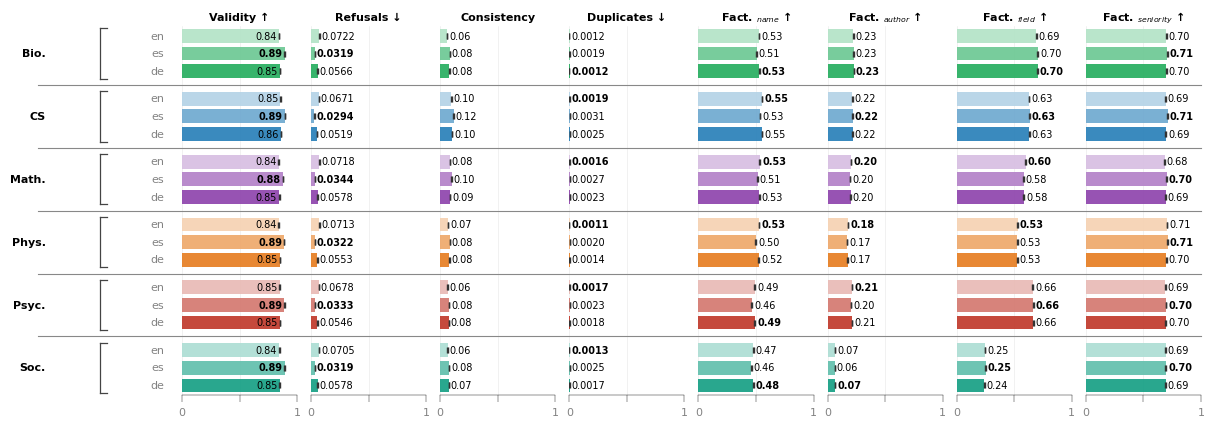

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_field_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_field_lang.pdf


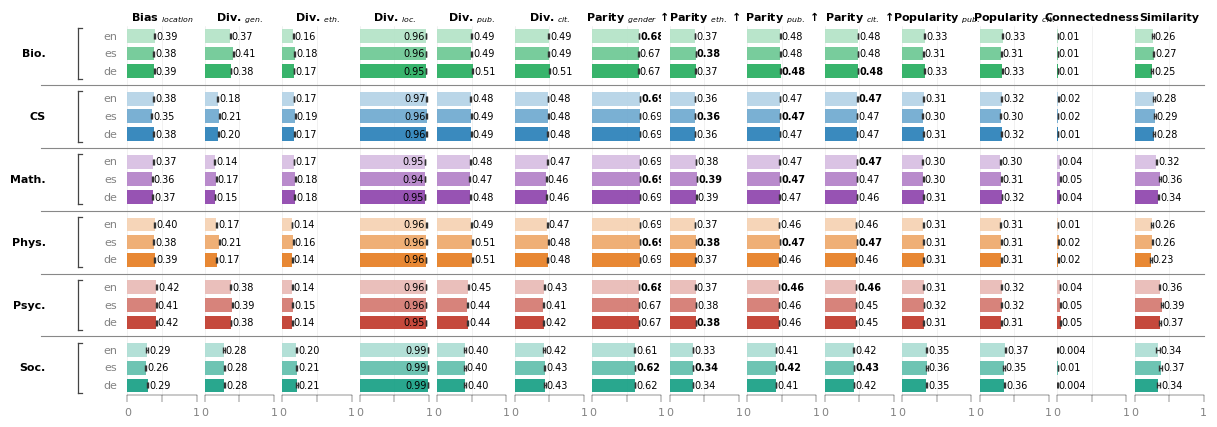

In [23]:

df_field_lang = aggregate_scores(df_valid_calls, ['field_en', 'language_en'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_field_lang.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_field_lang,
        group_configs=[
            {'label': FIELD_MAP[field_en], 
             'column': 'language_en', 
             'color': FIELD_COLORS[field_en], 
             'filter': {'field_en': field_en}, 
             'order': LANGUAGE_ORDER } for field_en in FIELD_ORDER
        ],
        row_labels=LANGUAGE_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * len(FIELD_ORDER))
    )


### Field and K

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_field_k.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_field_k.pdf


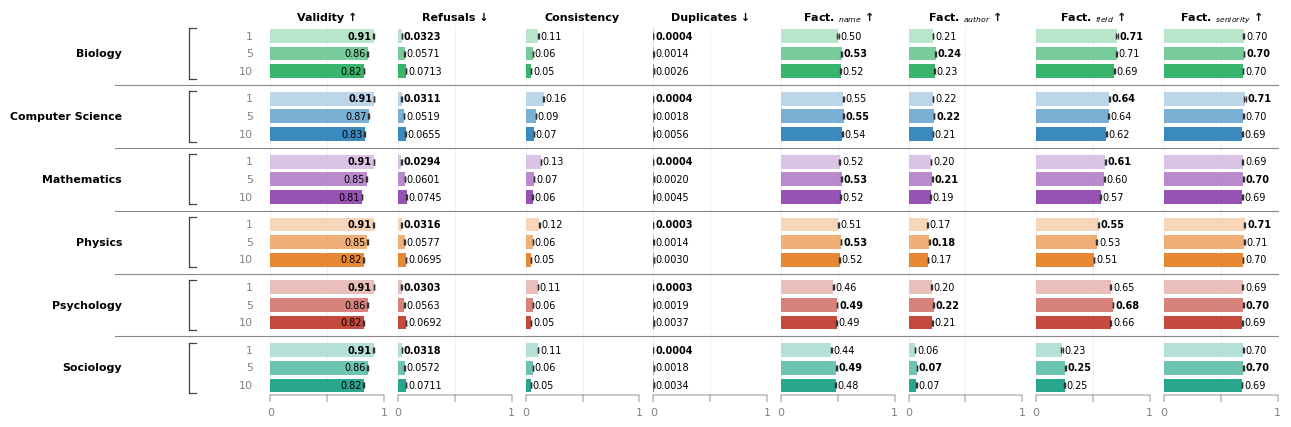

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_field_k.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_field_k.pdf


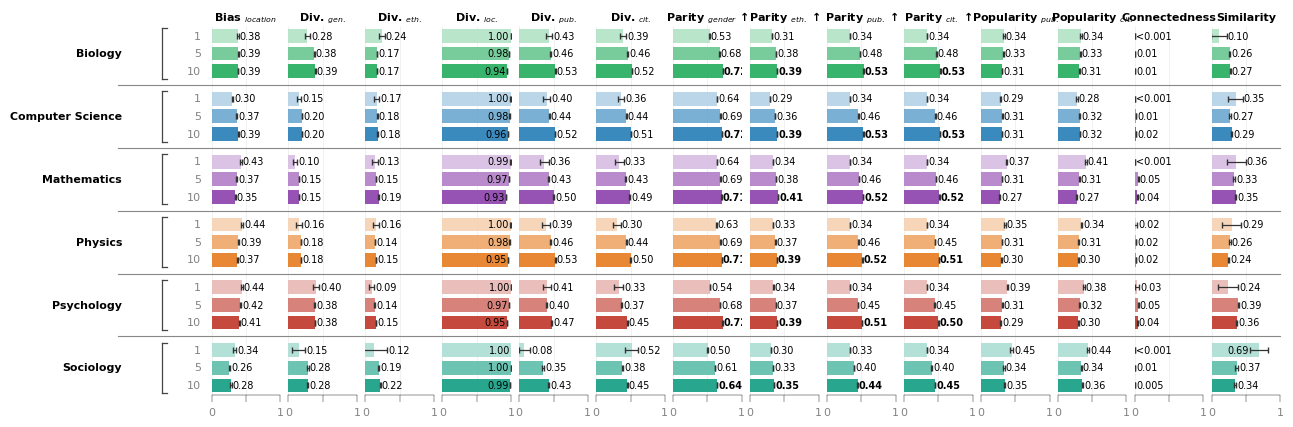

In [24]:

df_field_k = aggregate_scores(df_valid_calls, ['field_en', 'k'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_field_k.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_field_k,
        group_configs=[
            {'label': field_en, 
             'column': 'k', 
             'color': FIELD_COLORS[field_en], 
             'filter': {'field_en': field_en}, 
             'order': K_ORDER } for field_en in FIELD_ORDER
        ],
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * len(FIELD_ORDER)),
        textwrap_width=20
    )


## Subfield

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_subfield.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_subfield.pdf


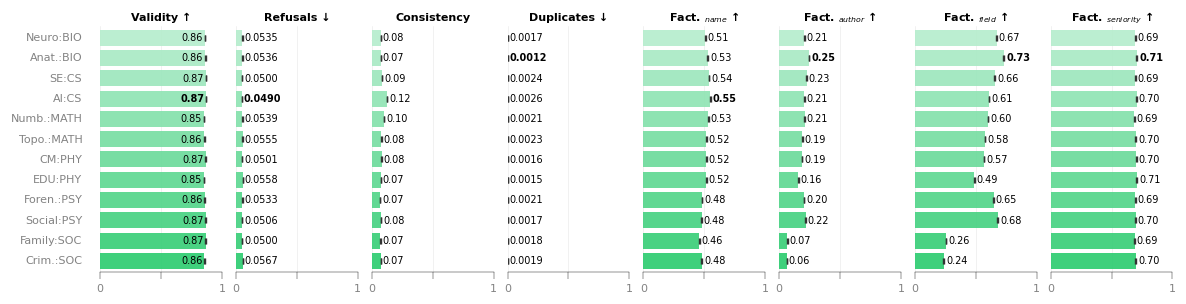

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_subfield.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_subfield.pdf


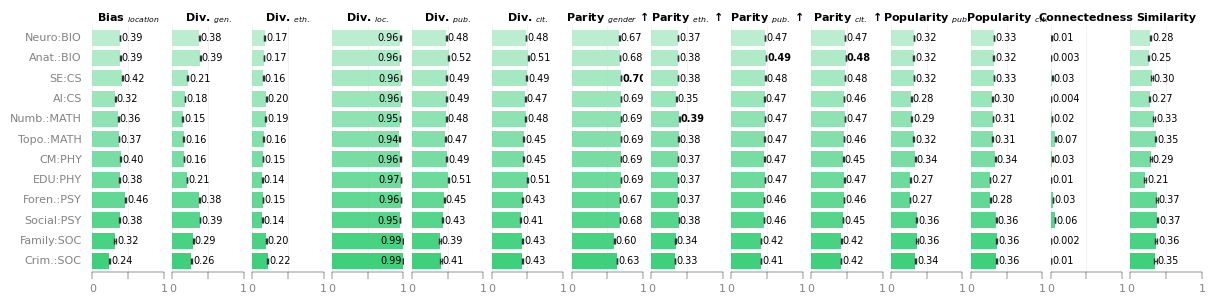

In [25]:

df_subfield = aggregate_scores(df_valid_calls, ['subfield_en'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_subfield.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_subfield,
        group_configs=[
            {'label': 'Subfield', 
             'column': 'subfield_en', 
             'color': '#2ECC71', 
             'order': SUBFIELD_ORDER},
        ],
        row_labels=SUBFIELD_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT + (len(SUBFIELD_ORDER)/5))
    )


### Subfield and Language

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_subfield_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_subfield_lang.pdf


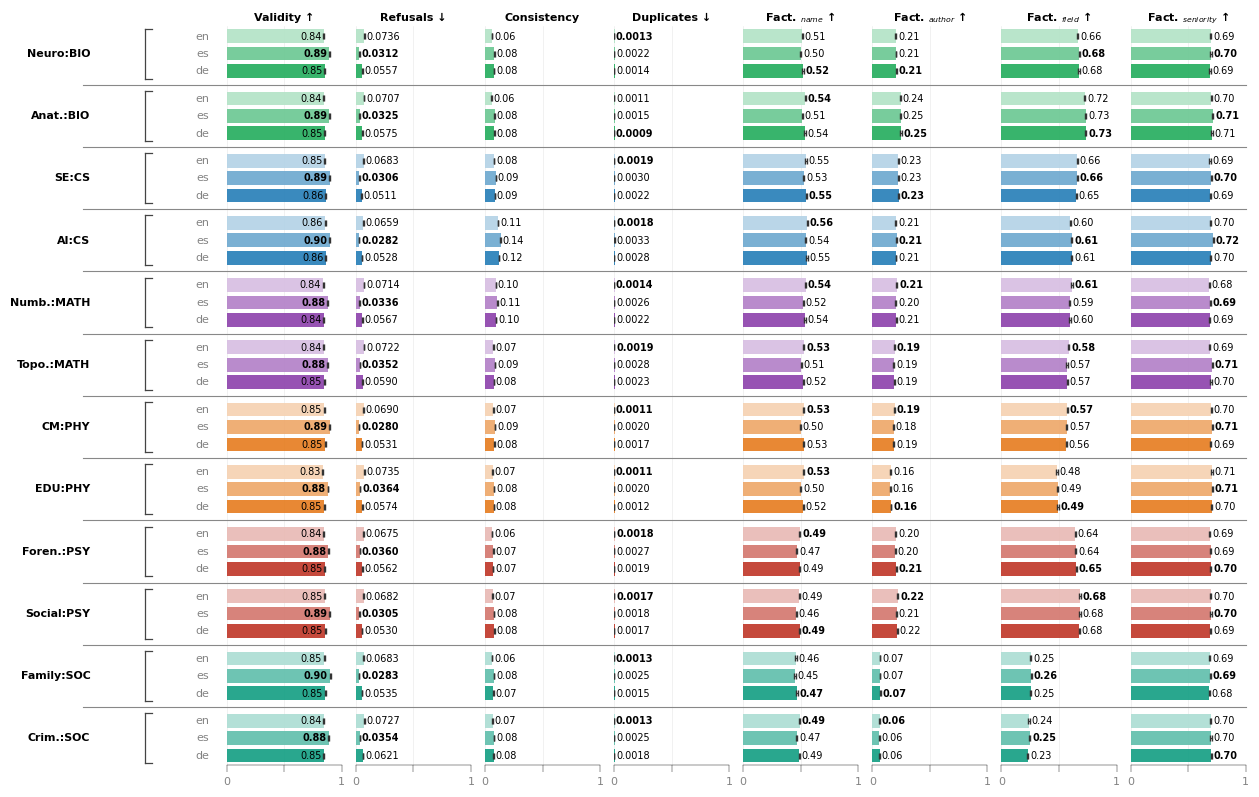

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_subfield_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_subfield_lang.pdf


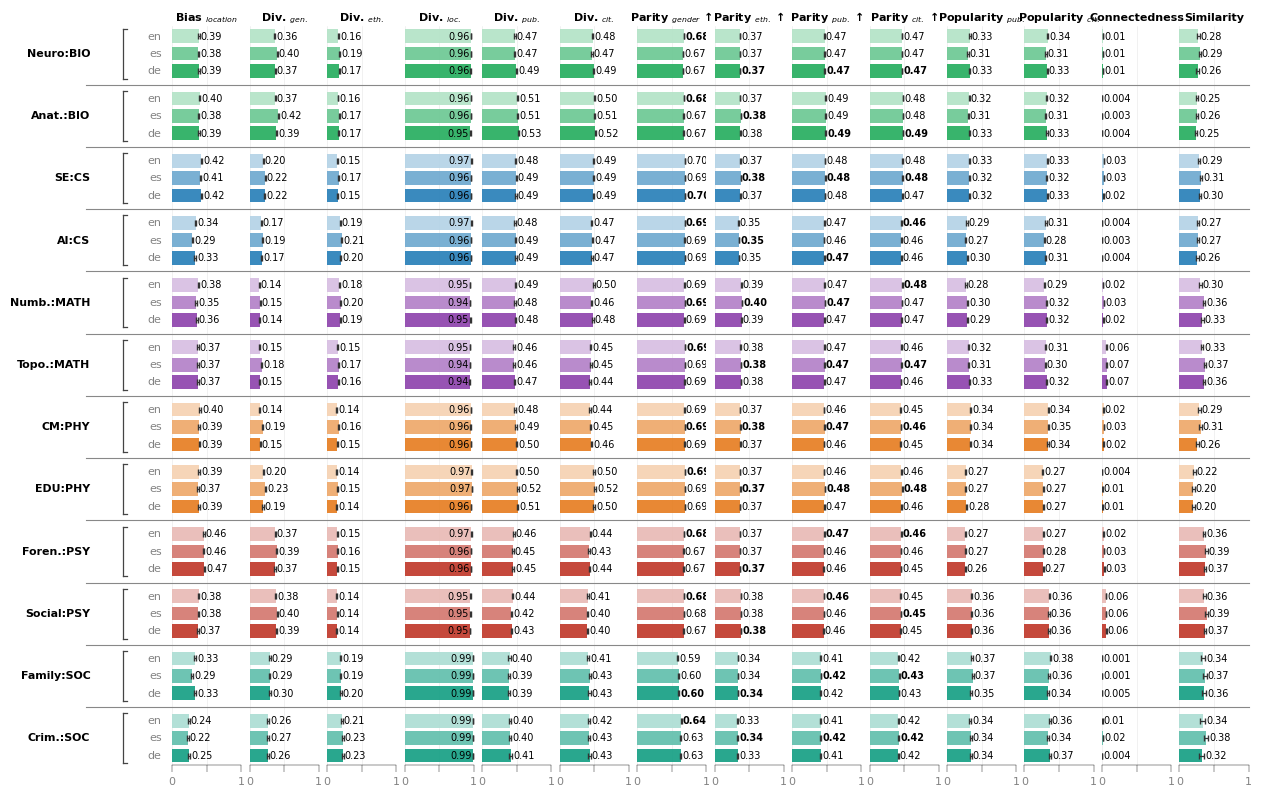

In [26]:

df_subfield_lang = aggregate_scores(df_valid_calls, ['subfield_en', 'language_en'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_subfield_lang.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_subfield_lang,
        group_configs=[
            {'label': SUBFIELD_MAP[subfield_en], 
             'column': 'language_en', 
             'color': SUBFIELD_COLORS[subfield_en], 
             'filter': {'subfield_en': subfield_en}, 
             'order': LANGUAGE_ORDER } for subfield_en in SUBFIELD_ORDER
        ],
        row_labels=LANGUAGE_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * len(SUBFIELD_ORDER))
    )


## Target (seniority)

,target_en,n,validity_mean,validity_ci,validity_std,refusals_mean,refusals_ci,refusals_std,connectedness_mean,connectedness_ci,connectedness_std,similarity_mean,similarity_ci,similarity_std,consistency_mean,consistency_ci,consistency_std,duplicates_mean,duplicates_ci,duplicates_std,...,pct_works_med_ci,pct_works_med_std,pct_works_high_mean,pct_works_high_ci,pct_works_high_std,pct_citations_low_mean,pct_citations_low_ci,pct_citations_low_std,pct_citations_med_mean,pct_citations_med_ci,pct_citations_med_std,pct_citations_high_mean,pct_citations_high_ci,pct_citations_high_std,popularity_works_mean,popularity_works_ci,popularity_works_std,popularity_citations_mean,popularity_citations_ci,popularity_citations_std
0,Junior Professor,464400,0.8565,0.0010,0.3506,0.0575,0.0007,0.2328,0.0003,0.0001,0.0148,0.5052,0.0052,0.5617,0.0713,0.0004,0.1457,0.0017,0.0001,0.0332,...,0.0024,0.3849,0.0646,0.0013,0.2184,0.6453,0.0025,0.4131,0.2874,0.0024,0.3883,0.0673,0.0014,0.2229,0.0646,0.0013,0.2184,0.0673,0.0014,0.2229
1,Senior Professor,464400,0.8672,0.0010,0.3394,0.0478,0.0006,0.2133,0.0356,0.0009,0.1449,0.2106,0.0036,0.5577,0.0931,0.0005,0.1741,0.0021,0.0001,0.0339,...,0.0018,0.3705,0.4703,0.0020,0.4088,0.2005,0.0016,0.3277,0.3236,0.0018,0.3787,0.4758,0.0020,0.4121,0.4703,0.0020,0.4088,0.4758,0.0020,0.4121


technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_seniority.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_seniority.pdf


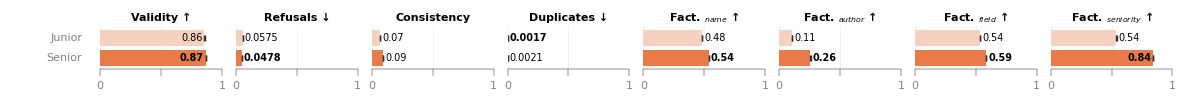

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_seniority.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_seniority.pdf


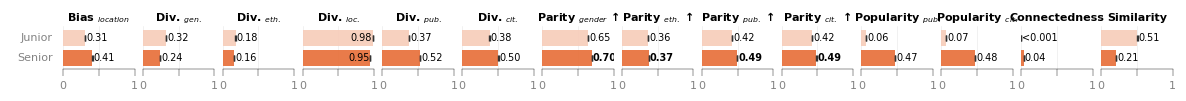

In [27]:

df_target = aggregate_scores(df_valid_calls, ['target_en'])
display(df_target)

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_seniority.pdf')
    print(fn)
        
    plot_grouped_metrics_labeled(
        df_target,
        group_configs=[
            {'label': 'Target', 
             'column': 'target_en', 
             'color': '#E8703A',
             'order': SENIORITY_ORDER},
        ],
        row_labels=SENIORITY_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * 0.7)
    )

### Seniority and Language

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_seniority_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_seniority_lang.pdf


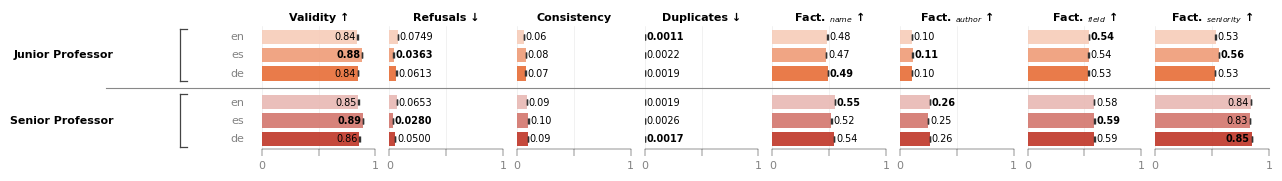

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_seniority_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_seniority_lang.pdf


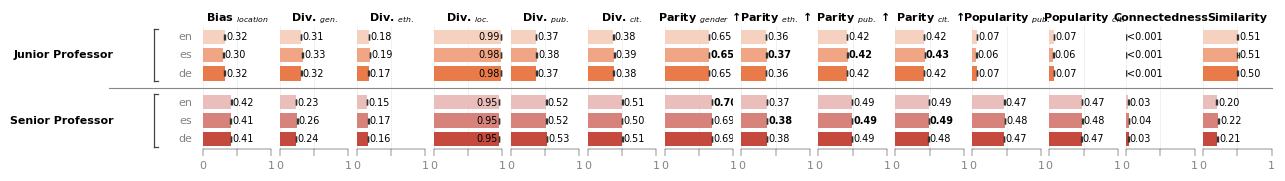

In [28]:

df_target_lang = aggregate_scores(df_valid_calls, ['target_en', 'language_en'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_seniority_lang.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_target_lang,
        group_configs=[
            {'label': target_en, 
             'column': 'language_en', 
             'color': SENIORITY_COLORS[target_en],
            'filter': {'target_en': target_en}, 
            'order': LANGUAGE_ORDER}
            for target_en in SENIORITY_ORDER
        ],
        row_labels=LANGUAGE_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * len(SENIORITY_ORDER)),
        textwrap_width=20
    )

## Model

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_model.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_model.pdf


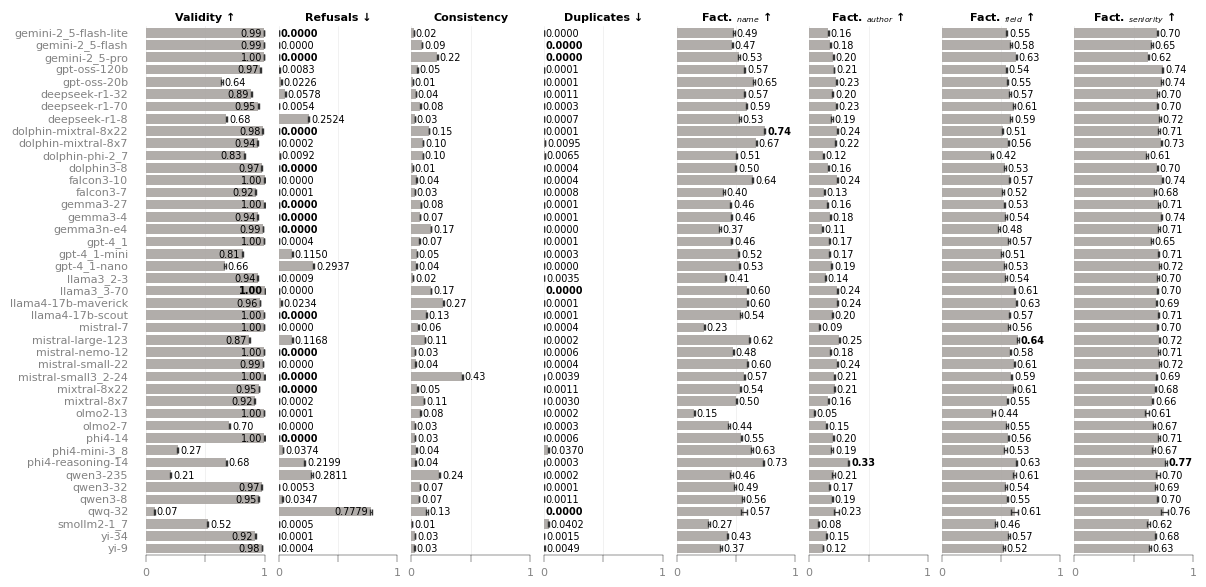

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_model.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_model.pdf


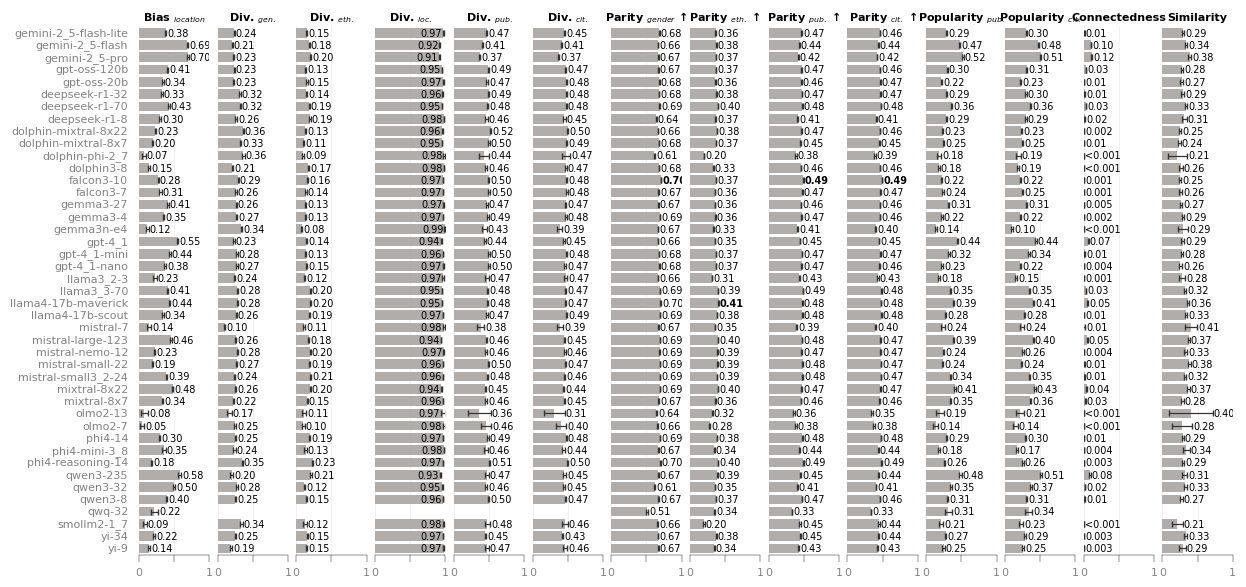

In [29]:

df_model = aggregate_scores(df_valid_calls, ['model_short_name'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_model.pdf')
    print(fn)
        
    plot_grouped_metrics_labeled(
        df_model,
        group_configs=[
            {'label': 'Model', 
             'column': 'model_short_name', 
             'color': "#ABA6A3",'order': MODELS,
             'shade': False}
        ],
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * (len(MODELS)/5)),
        textwrap_width = 25,
    )

### Model and Language

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_model_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_model_lang.pdf


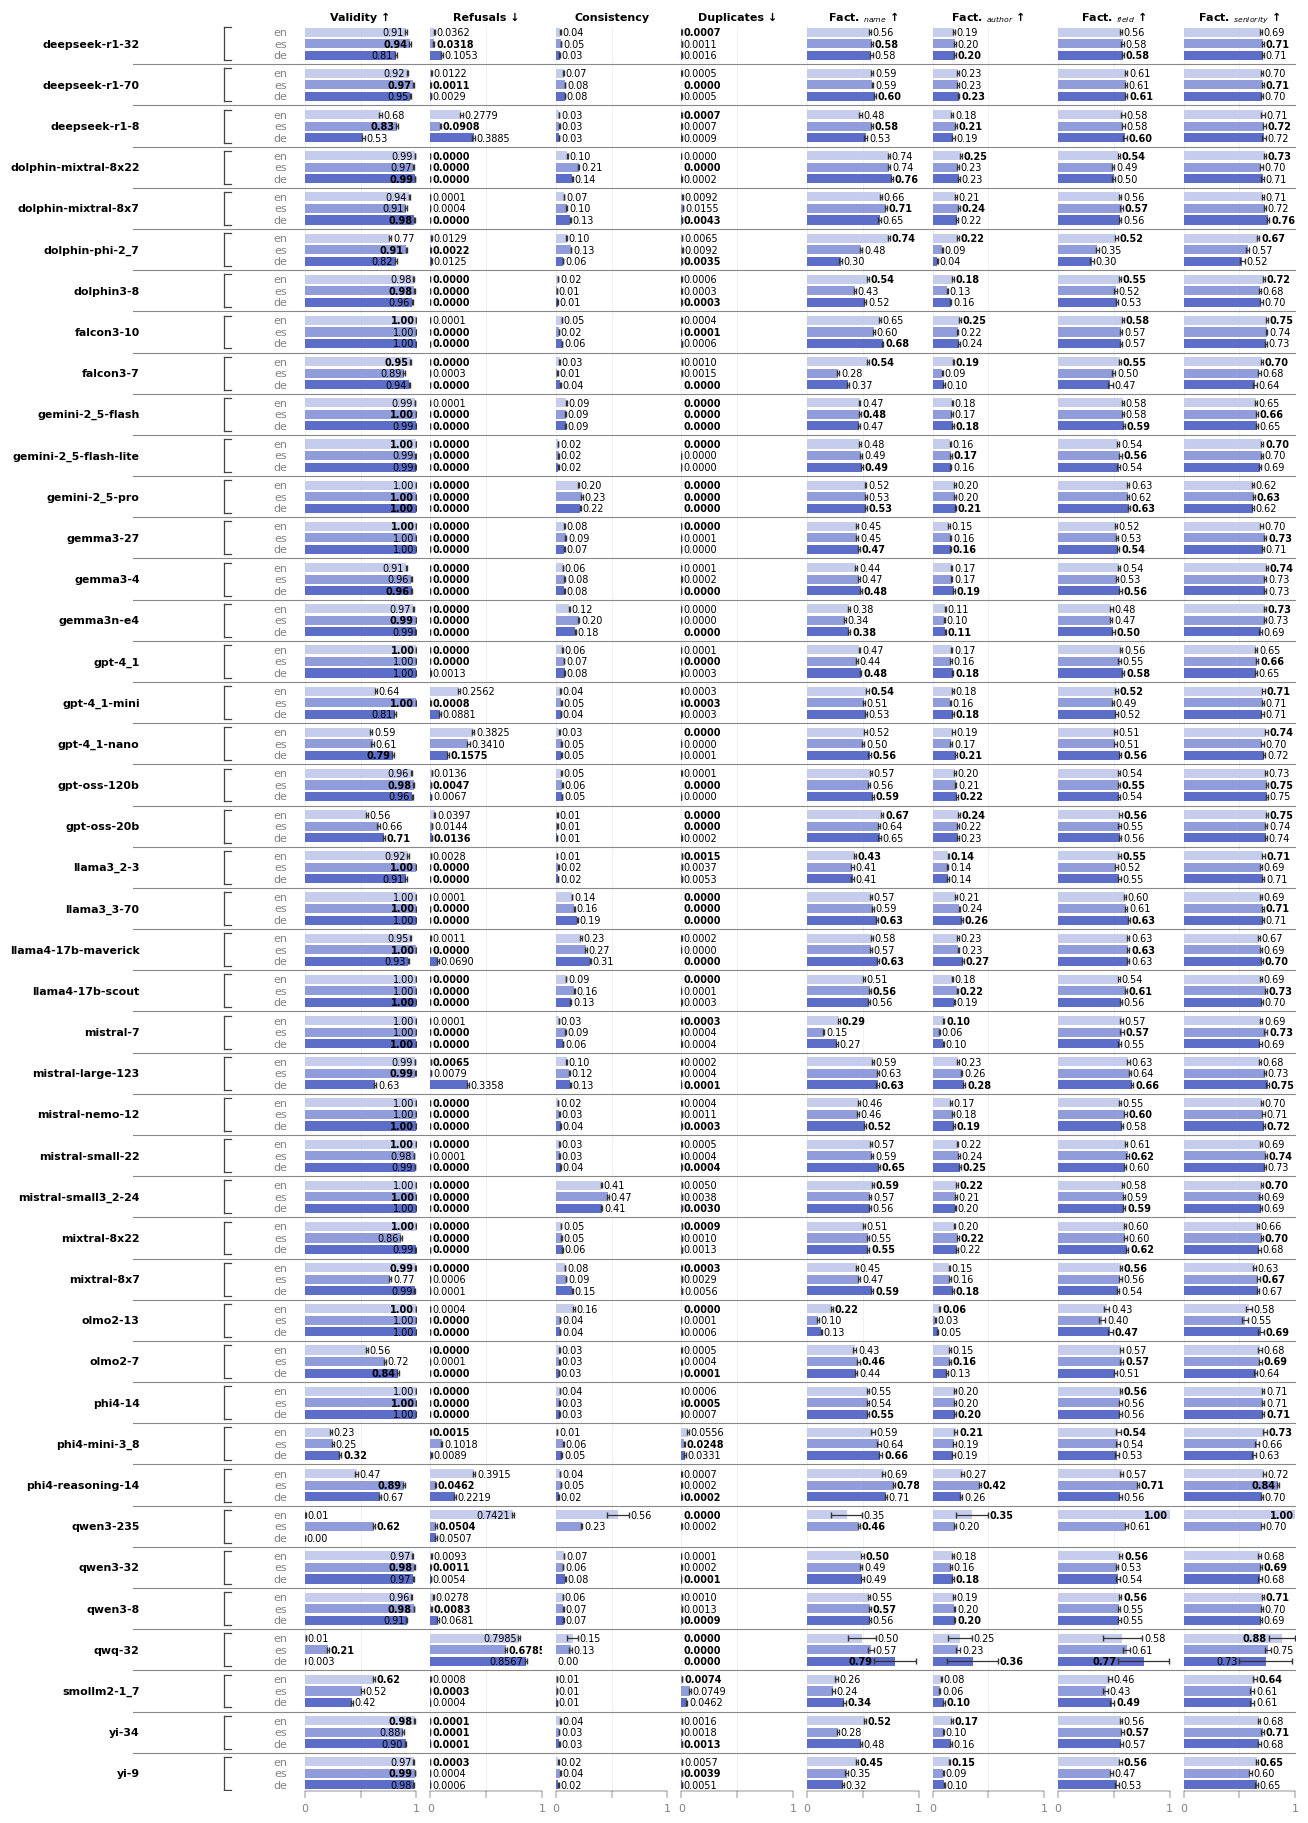

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_model_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_model_lang.pdf


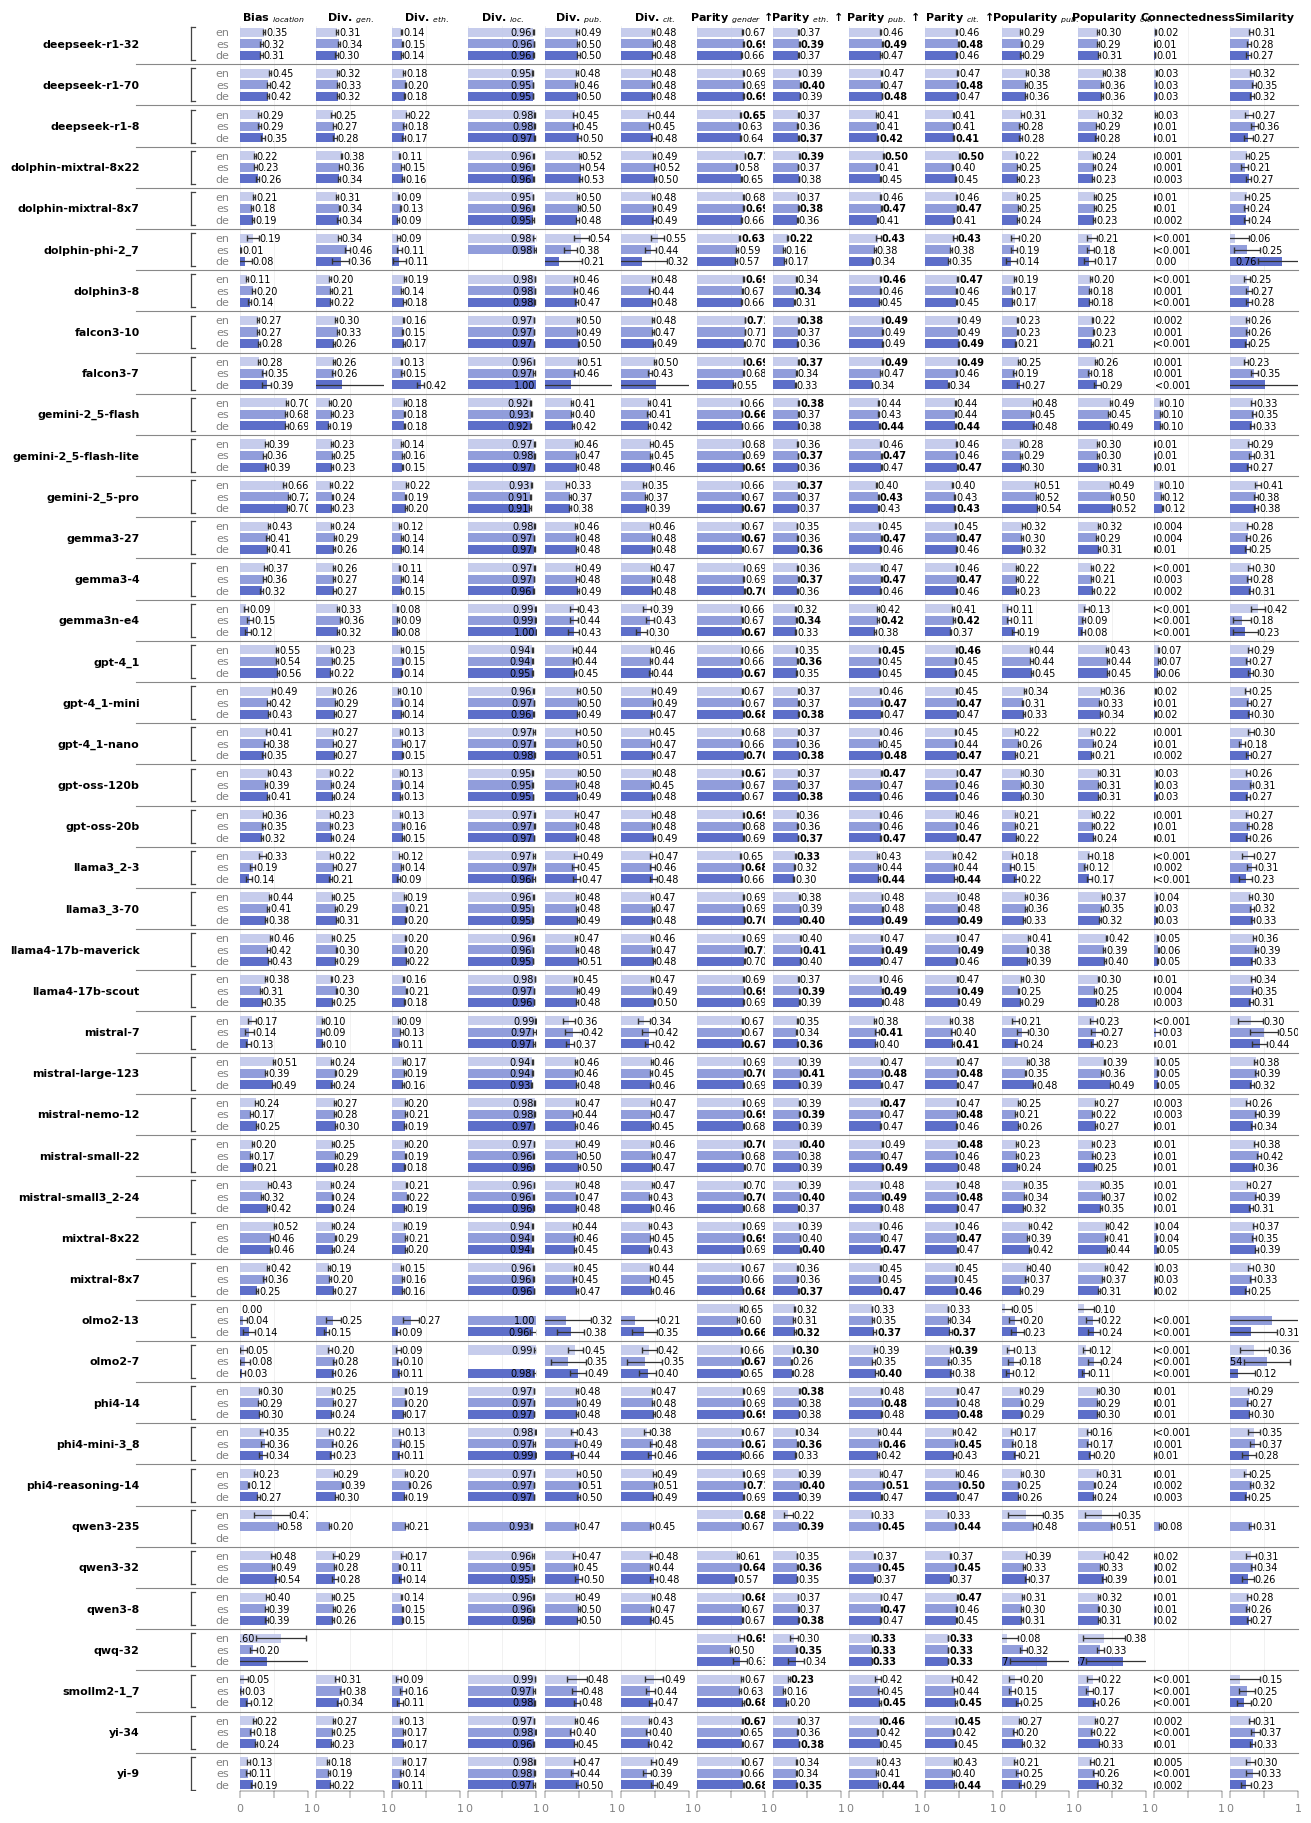

In [30]:
df_model_lang = aggregate_scores(df_valid_calls, ['model_short_name', 'language_en'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_model_lang.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_model_lang,
        group_configs=[
            {'label': model, 
             'column': 'language_en', 
             'color': "#4F62C5",
            'filter': {'model_short_name': model}, 
            'order': LANGUAGE_ORDER}
            for model in df_model_lang.model_short_name.unique()
        ],
        row_labels=LANGUAGE_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * len(MODELS)/1.5),
        textwrap_width = 30
    )

## Model Family

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_modelfamily.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_modelfamily.pdf


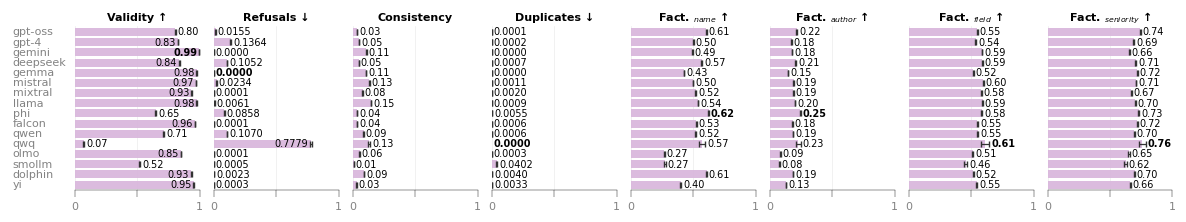

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_modelfamily.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_modelfamily.pdf


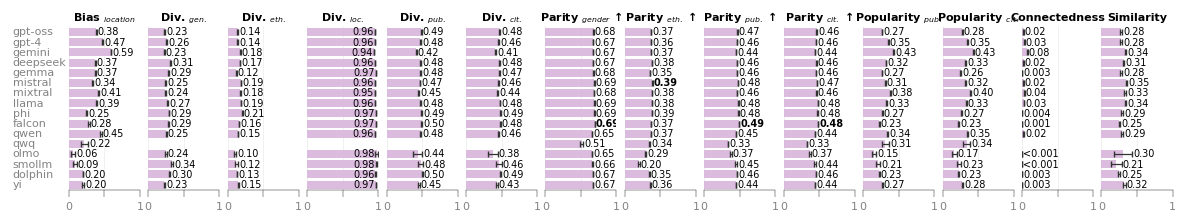

In [31]:
df_model_family = aggregate_scores(df_valid_calls, ['model_family'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_modelfamily.pdf')
    print(fn)
        
    plot_grouped_metrics_labeled(
        df_model_family,
        group_configs=[
            {'label': 'Model', 
             'column': 'model_family', 
             'color': "#D8B6DC",
             'order': MODEL_FAMILY_ORDER,
              'shade': False
             },
        ],
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * (len(df_model_family.model_family.unique())/6)),
        textwrap_width = 10,
        row_label_align='left',
        row_label_width=0.7,
        row_label_pad=0.22,
    )

### Model family and Language

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_modelfamily_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_modelfamily_lang.pdf


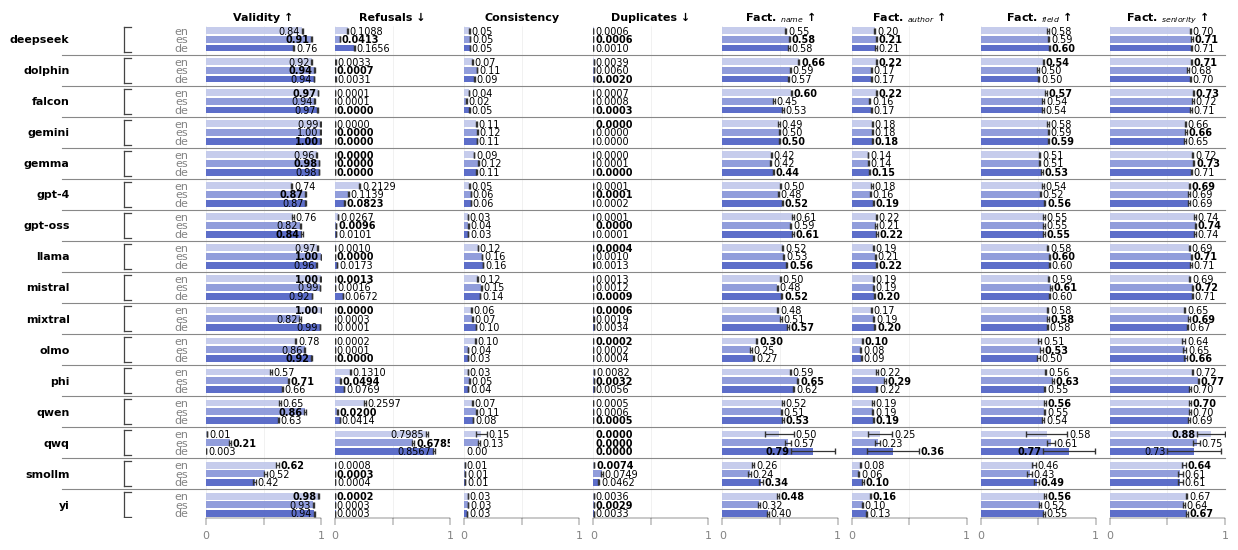

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_modelfamily_lang.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_modelfamily_lang.pdf


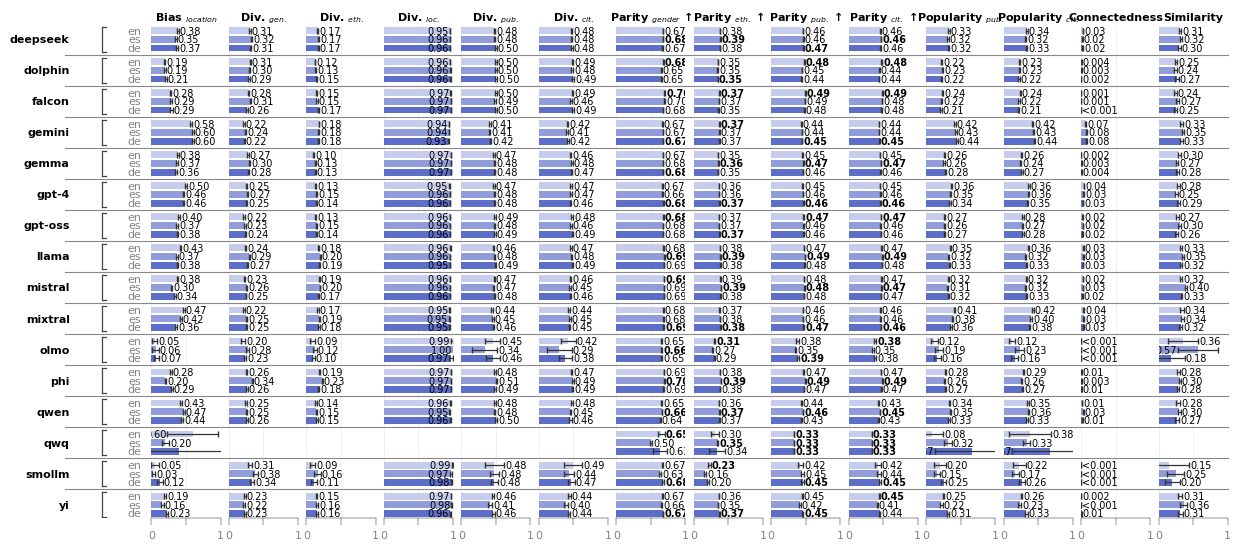

In [32]:
df_modelfamily_lang = aggregate_scores(df_valid_calls, ['model_family', 'language_en'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_modelfamily_lang.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_modelfamily_lang,
        group_configs=[
            {'label': model_family, 
             'column': 'language_en', 
             'color': "#4F62C5",
            'filter': {'model_family': model_family}, 
            'order': LANGUAGE_ORDER}
            for model_family in df_modelfamily_lang.model_family.unique()
        ],
        row_labels=LANGUAGE_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * df_modelfamily_lang.model_family.nunique()/2),
        textwrap_width = 12
    )

### Model familty and Country

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_modelfamily_loc.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_modelfamily_loc.pdf


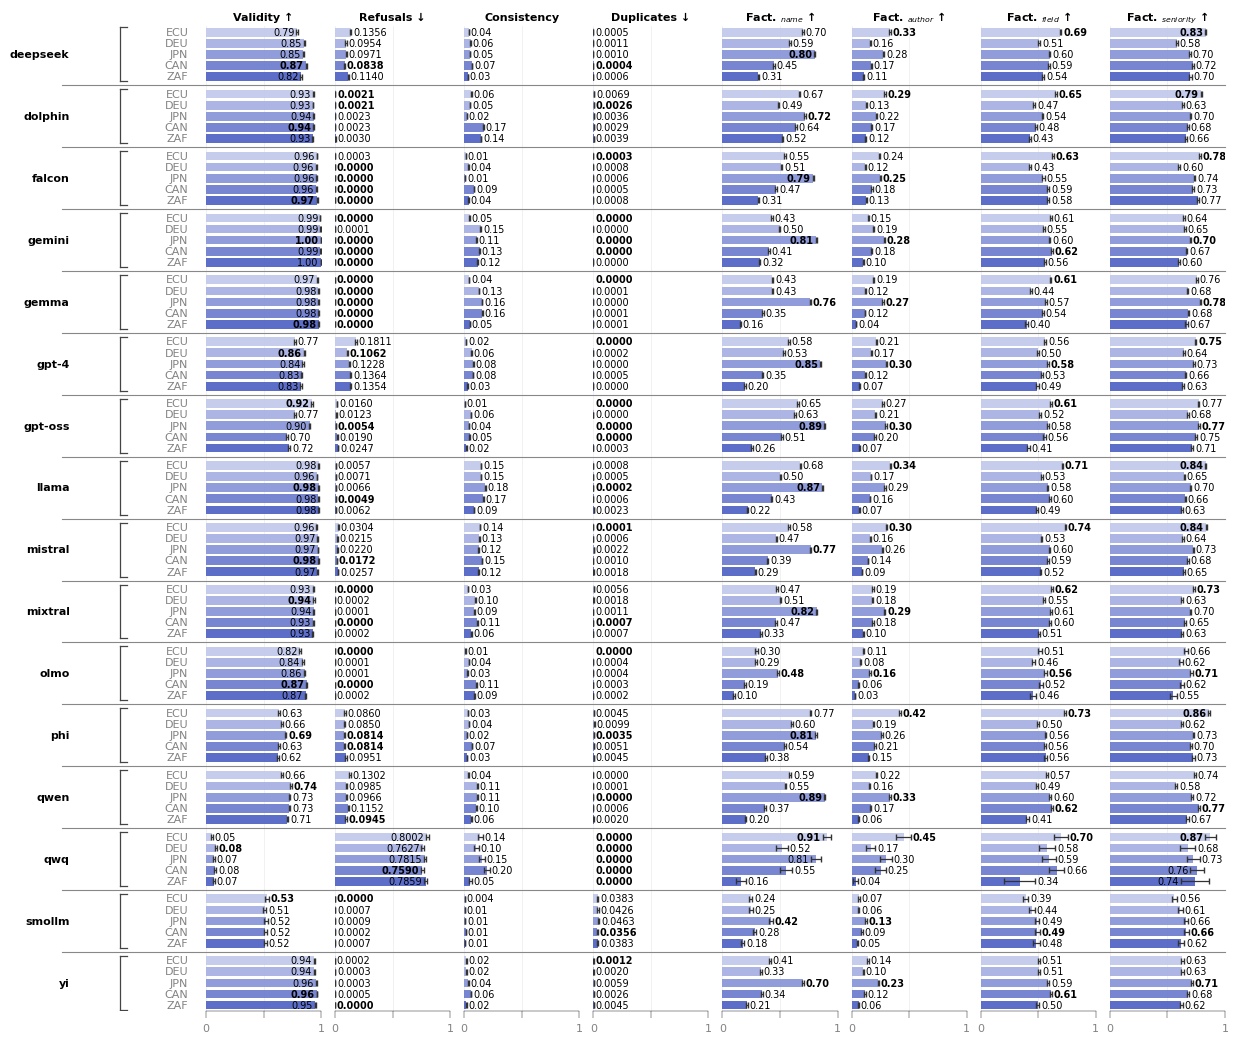

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_modelfamily_loc.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_modelfamily_loc.pdf


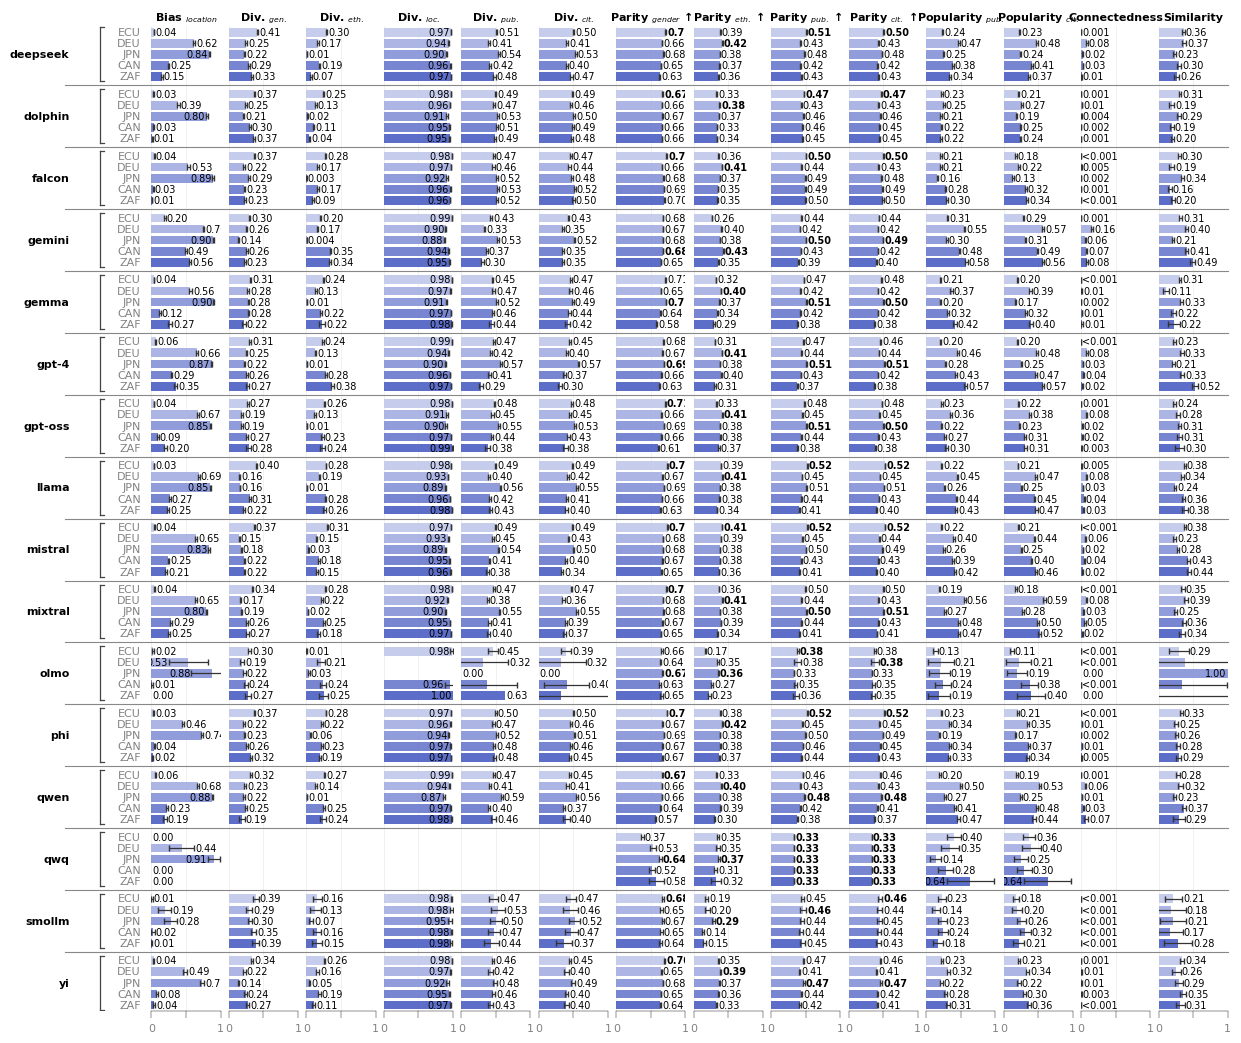

In [33]:
df_modelfamily_lang_loc = aggregate_scores(df_valid_calls, ['model_family', 'location_en'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_modelfamily_loc.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_modelfamily_lang_loc,
        group_configs=[
            {'label': model_family, 
             'column': 'location_en', 
             'color': "#4F62C5",
            'filter': {'model_family': model_family}, 
            'order': LOCATION_ORDER}
            for model_family in df_modelfamily_lang.model_family.unique()
        ],
        row_labels=LOCATION_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * df_modelfamily_lang.model_family.nunique()),
        textwrap_width = 12
    )

### Model family and Seniority

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_modelfamily_target.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_modelfamily_target.pdf


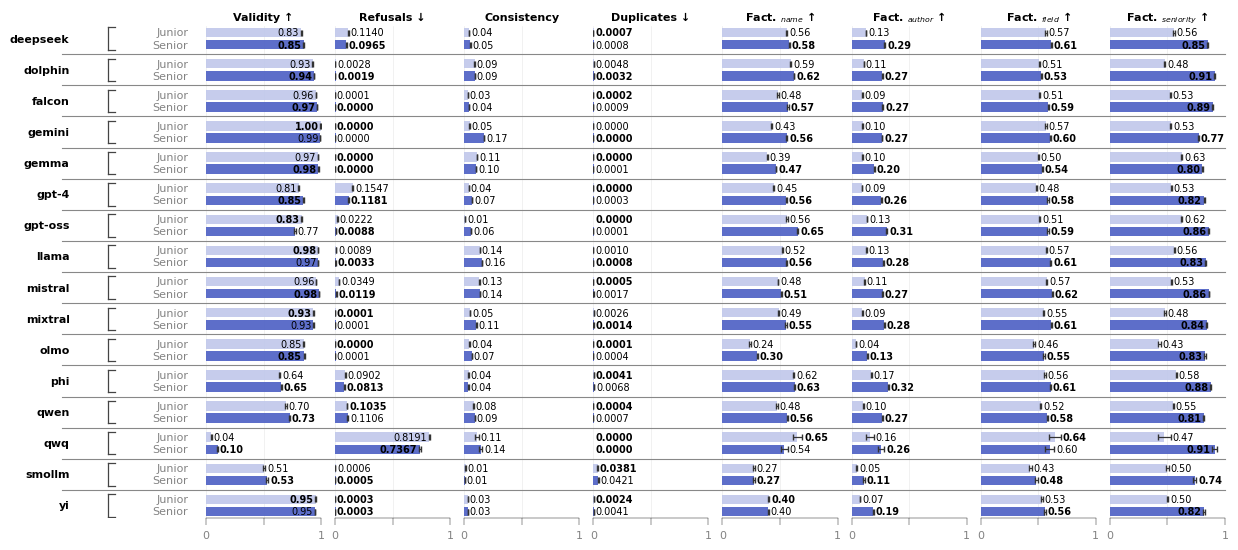

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_modelfamily_target.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_modelfamily_target.pdf


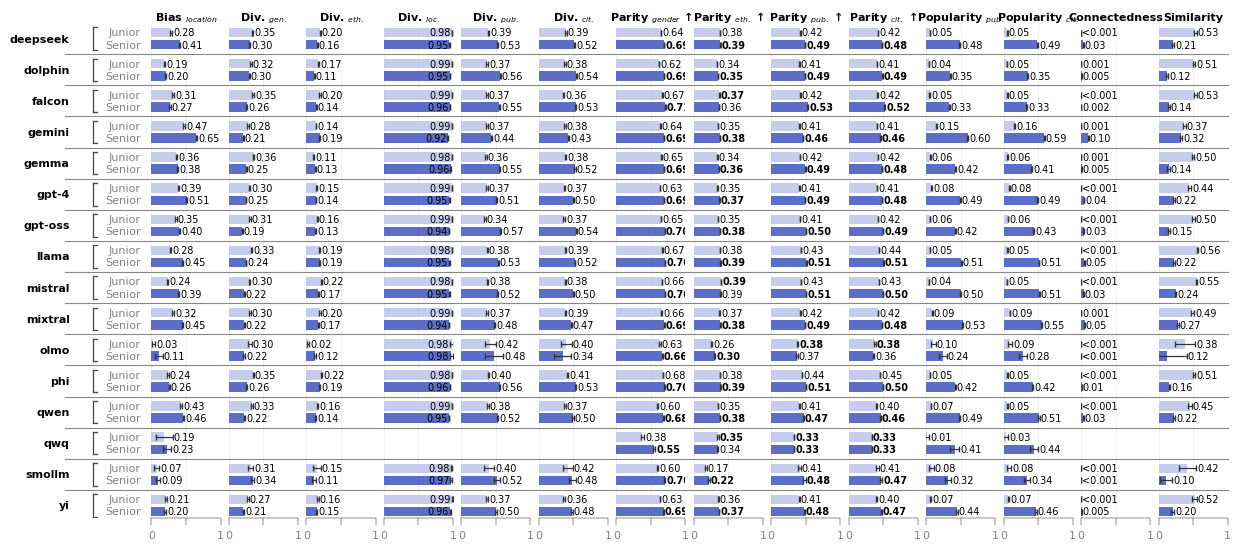

In [34]:
df_modelfamily_lang_target = aggregate_scores(df_valid_calls, ['model_family', 'target_en'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_modelfamily_target.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_modelfamily_lang_target,
        group_configs=[
            {'label': model_family, 
             'column': 'target_en', 
             'color': "#4F62C5",
            'filter': {'model_family': model_family}, 
            'order': SENIORITY_ORDER}
            for model_family in df_modelfamily_lang.model_family.unique()
        ],
        row_labels=SENIORITY_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * df_modelfamily_lang.model_family.nunique()/2),
        textwrap_width = 12
    )

### Model familty and Field

technical
/code/asanchez/LLMScholar-Personas/results/plots/plot_technical_modelfamily_field.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_technical_modelfamily_field.pdf


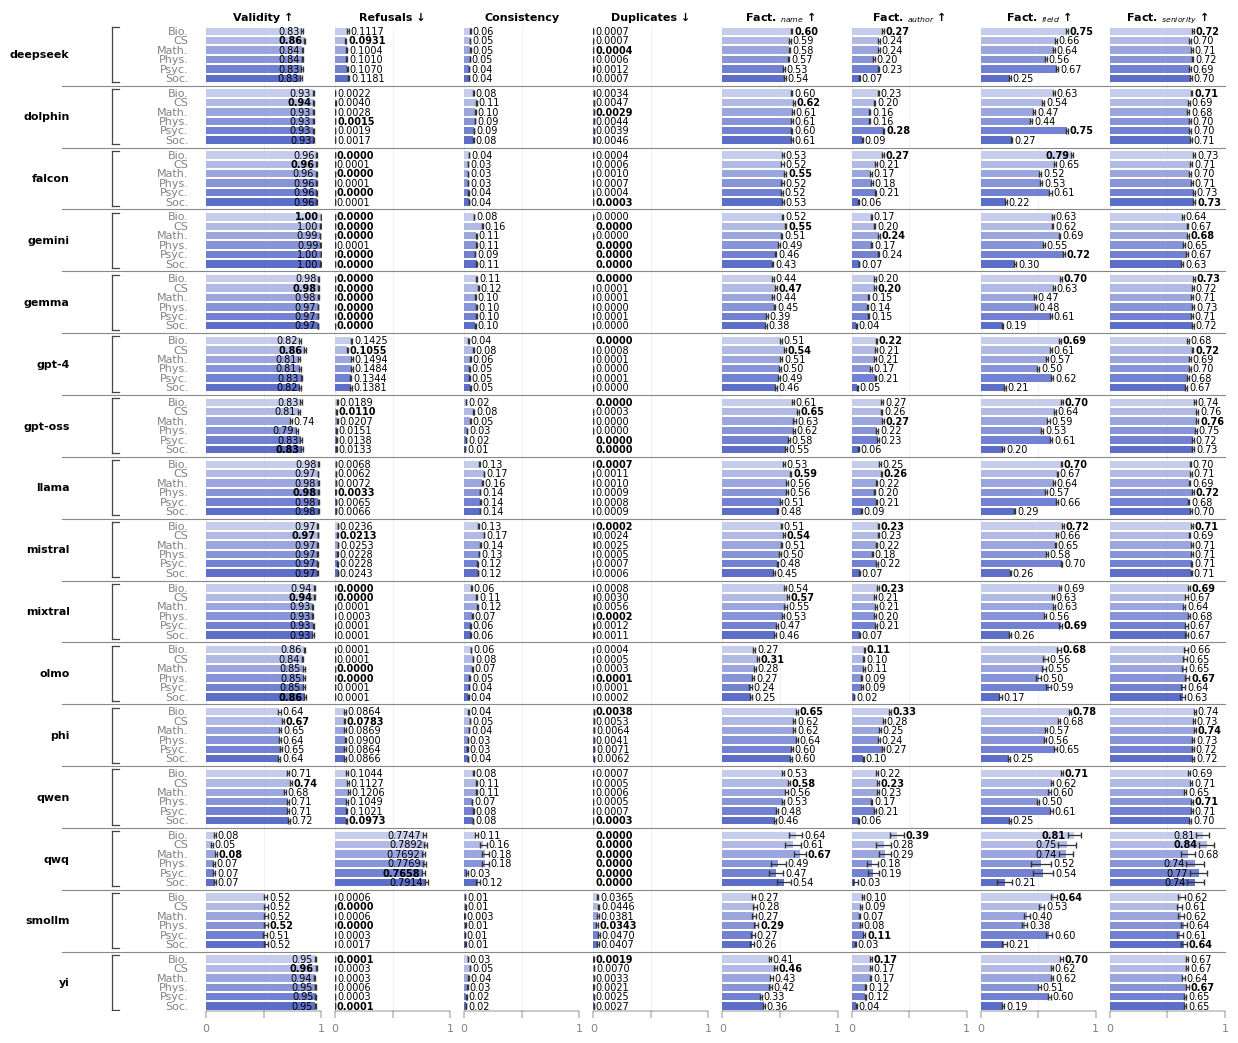

social
/code/asanchez/LLMScholar-Personas/results/plots/plot_social_modelfamily_field.pdf
Saved → /code/asanchez/LLMScholar-Personas/results/plots/plot_social_modelfamily_field.pdf


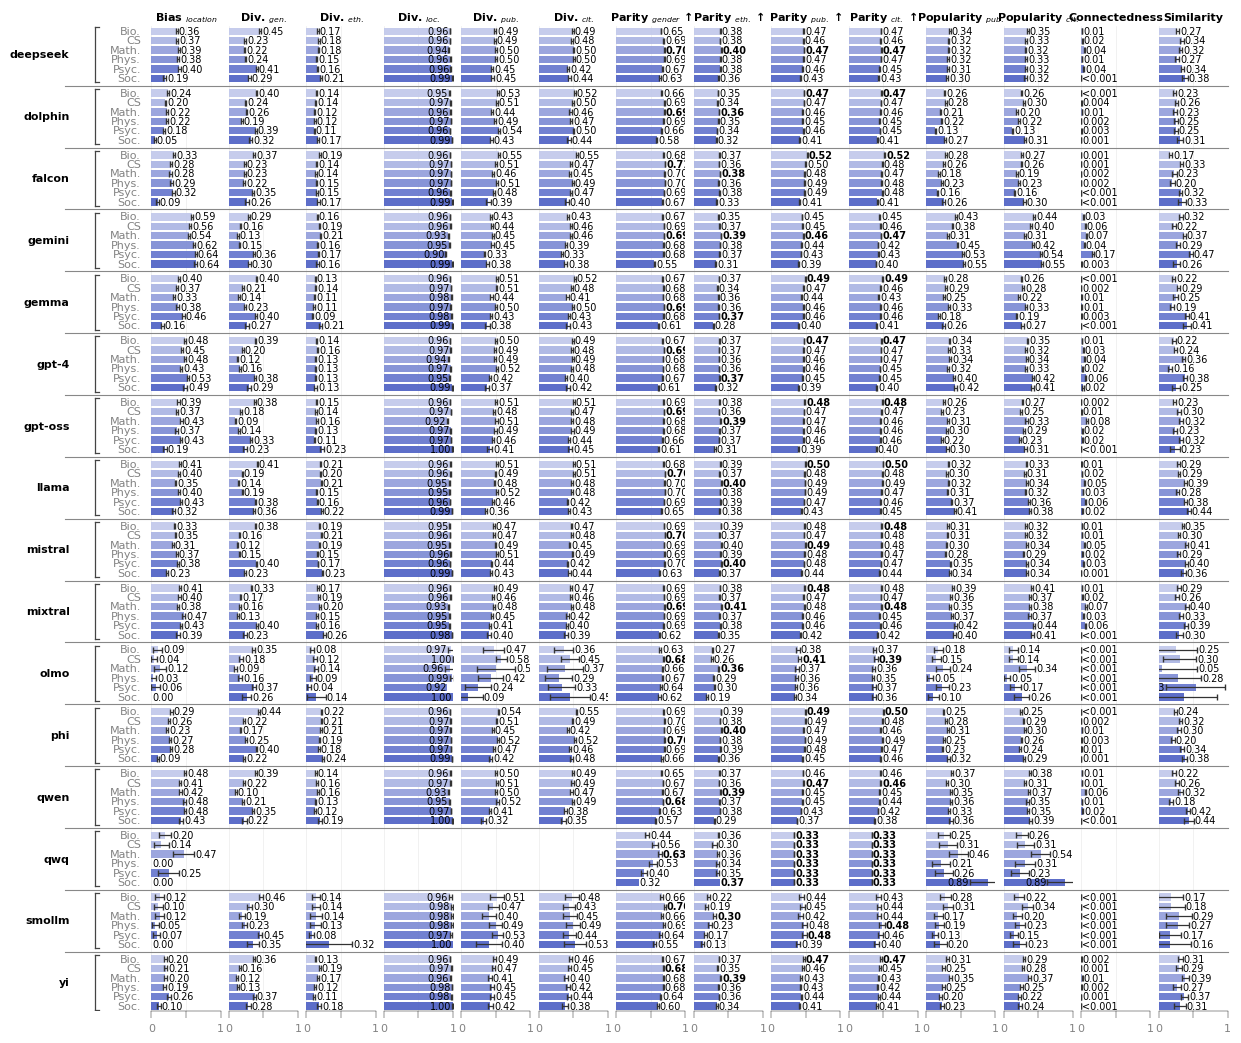

In [35]:
df_modelfamily_lang_field = aggregate_scores(df_valid_calls, ['model_family', 'field_en'])

for metric_type, metric_list in METRIC_TYPES.items():
    
    print(metric_type)
    
    fn = str(PLOTS_DIR / f'plot_{metric_type}_modelfamily_field.pdf')
    print(fn)

    plot_grouped_metrics_labeled(
        df_modelfamily_lang_field,
        group_configs=[
            {'label': model_family, 
             'column': 'field_en', 
             'color': "#4F62C5",
            'filter': {'model_family': model_family}, 
            'order': FIELD_ORDER}
            for model_family in df_modelfamily_lang.model_family.unique()
        ],
        row_labels=FIELD_MAP,
        metrics=metric_list,
        metric_directions=METRIC_DIRECTIONS,
        metric_labels=PLOT_LABELS,
        save_path=fn,
        figsize=(FIG_WIDTH, FIG_HEIGHT * df_modelfamily_lang.model_family.nunique()),
        textwrap_width = 12
    )

## Structural metrics: connectedness & similarity

Paper Eqs. 6-8. Both are computed over `Û_i`, the unique authors of a response whose name exists in Semantic Scholar or OpenAlex,
and both are **undefined (NaN) when fewer than 2 of those authors are evaluable** —
connectedness because `log n = 0` at n=1, similarity because there is no pair.

Two structural reasons produce most of the NaNs, and neither is a bug:

1. **`k = 1` can never yield a value.** One recommendation means at most one author, so
   a third of the experiment is NaN by construction.
2. **Authors matched only in Semantic Scholar have no `oa_id`**, hence no graph node and
   no feature vector, so they are excluded and counted (`n_excluded_*`).

Use `n_used_*` as the denominator, **not** `n_authors_found`: the latter collapses every
author without an `oa_id` into a single entry, so subtracting the two goes negative.

In [36]:
# Coverage diagnostic: where the NaNs come from, and how the two metrics are distributed.
for m in STRUCTURAL_METRICS:
    s = df_valid_calls[m]
    print(f'{m}: defined for {s.notna().sum():,}/{len(s):,} responses ({100*s.notna().mean():.1f}%)')
    print(f'   mean={s.mean():.4f}  median={s.median():.4f}  '
          f'min={s.min():.4f}  max={s.max():.4f}')

# k=1 is NaN by construction — one recommendation cannot make a pair.
print('\ncoverage by k (share of responses with a defined value):')
display(df_valid_calls.groupby('k')[STRUCTURAL_METRICS]
        .apply(lambda g: g.notna().mean().round(4)))

# n_used is the denominator of Eqs. 6-8; >=2 exactly when the metric is defined.
print('exclusions and denominator:')
_cols = list(STRUCTURAL_EXCLUSION_COLS.values()) + list(STRUCTURAL_USED_COLS.values())
display(df_valid_calls[_cols].describe().loc[['mean', 'max']].round(3))

# The two metrics are only weakly related, so they are not redundant.
_sub = df_valid_calls[STRUCTURAL_METRICS].dropna()
print(f"pearson(connectedness, similarity) = {_sub.corr().iloc[0, 1]:.4f}")

connectedness: defined for 135,957/928,800 responses (14.6%)
   mean=0.0241  median=0.0000  min=0.0000  max=1.0000
similarity: defined for 135,957/928,800 responses (14.6%)
   mean=0.3064  median=0.3180  min=-0.9999  max=1.0000

coverage by k (share of responses with a defined value):


,connectedness,similarity
k,,
1,0.0022,0.0022
5,0.1716,0.1716
10,0.2654,0.2654


exclusions and denominator:


,n_excluded_connectedness,n_excluded_similarity,n_used_connectedness,n_used_similarity
mean,0.3720,0.3720,1.7790,1.7790
max,23.0000,23.0000,11.0000,11.0000


pearson(connectedness, similarity) = 0.1248


## Location flows (Sankey) — issue #37

Where the recommended authors are actually based, given the country embedded in the
prompt. Built from `location_flows.csv` (`scripts/8_plot_data/build_location_flows.py`),
which keeps one row per (prompt country, author country, field, language, model), so
the figure can be sliced without re-reading `factuality_full.csv`.

Each source is normalised to 100%, so ribbon widths — and the `%` printed on each ribbon
— read as *"% of times a country R appears in the recommendations for country C"*, the
question the issue asks. Without normalising, a prompt country with more resolvable
authors would look more biased just for being bigger.

The five prompted countries are pinned on the right (`keep=LOCATION_ISO_ORDER`): Ecuador
is small enough that a plain top-N folds it into `Other`, and EC→EC is exactly the cell
we want to read. The tail beyond that is still folded into `Other` rather than dropped.
Authors whose OpenAlex record has no country (15.2% of factual recommendations) cannot
enter a flow and are excluded. The full source × target matrix is printed under the
figure.

Loaded 37,996 flow rows | 426,899 recommendations
/code/asanchez/LLMScholar-Personas/results/plots/plot_location_sankey.pdf


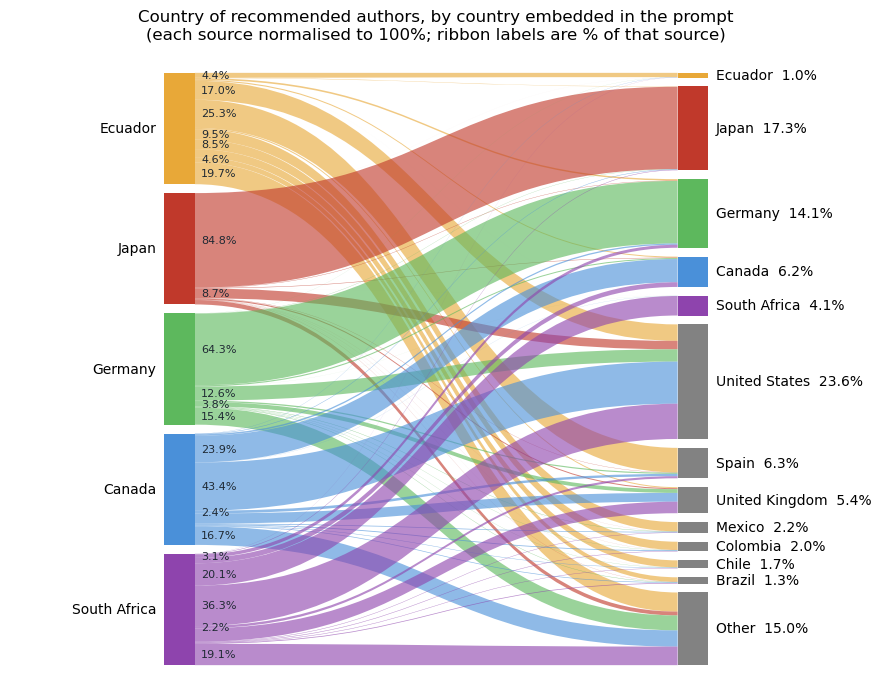


% of each prompt country's recommendations, by author country
dst_iso     EC      JP      DE      CA      ZA      US      ES      GB     MX     CO     CL     BR   Other
src_iso                                                                                                   
EC      4.4000  0.3000  1.5000  1.0000  0.0000 17.0000 25.3000  1.0000 9.5000 8.5000 7.2000 4.6000 19.7000
JP      0.0000 84.8000  0.4000  0.4000  0.0000  8.7000  0.3000  1.0000 0.1000 0.1000 0.0000 0.2000  4.0000
DE      0.1000  0.2000 64.3000  1.0000  0.0000 12.6000  1.2000  3.8000 0.4000 0.2000 0.2000 0.4000 15.4000
CA      0.2000  0.5000  1.4000 23.9000  0.1000 43.4000  2.4000  9.0000 0.7000 0.8000 0.4000 0.6000 16.7000
ZA      0.1000  0.5000  3.1000  4.8000 20.1000 36.3000  2.2000 11.9000 0.4000 0.5000 0.4000 0.7000 19.1000


In [37]:
FLOWS_PATH = RESULTS / 'factualities/tables/location_flows.csv'
df_flows = pd.read_csv(FLOWS_PATH)
print(f'Loaded {len(df_flows):,} flow rows | {df_flows.n.sum():,} recommendations')

# ISO-2 on both sides; reuse the repo's per-country colours for the sources.
_iso2name = {v: k for k, v in LLM_COUNTRY_TO_ISO.items() if k in LOCATION_COLORS}
_src_labels = {i: _iso2name.get(i, i) for i in df_flows.src_iso.unique()}
_src_colors = {i: LOCATION_COLORS[_iso2name[i]]
               for i in df_flows.src_iso.unique() if i in _iso2name}

# Global destination volume, so every figure with countries on the right ranks
# the tail the same way regardless of how its own slice happens to fall.
_country_volume = df_flows.groupby('dst_iso').n.sum()


def country_target_style(targets, other_label='Other'):
    """One styling convention for any country column on the right of a Sankey.

    Same order everywhere (the five prompted countries first in the project's
    canonical order, then the rest by global volume, `other_label` last), the
    same English names from COUNTRY_ISO_NAMES, and the prompted countries in
    their own LOCATION_COLORS so the eye can tie a destination back to the
    left-hand column instead of losing it in the grey.
    """
    targets = set(targets)
    head = [c for c in LOCATION_ISO_ORDER if c in targets]
    tail = sorted((t for t in targets if t not in head and t != other_label),
                  key=lambda t: -_country_volume.get(t, 0))
    order = head + tail + ([other_label] if other_label in targets else [])
    labels = {t: COUNTRY_ISO_NAMES.get(t, t) for t in order}
    colors = {t: LOCATION_COLORS[_iso2name[t]] for t in order if t in _iso2name}
    return order, labels, colors


_agg = df_flows.groupby(['src_iso', 'dst_iso'], as_index=False).n.sum()
# Pin the five prompted countries on the right. Ecuador is the smallest of them
# and a plain top-N folds it into `Other` — which is precisely the cell the
# figure exists to show ("when the prompt says Ecuador, how often does an
# Ecuadorian come back?").
_agg = collapse_tail(_agg, target_col='dst_iso', value_col='n', top_n=12,
                     keep=LOCATION_ISO_ORDER)
_agg = normalize_by_source(_agg, source_col='src_iso', value_col='n')

_order, _dst_labels, _dst_colors = country_target_style(_agg.dst_iso.unique())

fig, ax = plot_sankey(
    _agg,
    source_col='src_iso', target_col='dst_iso', value_col='n',
    source_order=[i for i in LOCATION_ISO_ORDER if i in set(_agg.src_iso)],
    target_order=_order,
    source_colors=_src_colors,
    source_labels=_src_labels,
    target_labels=_dst_labels,
    target_colors=_dst_colors,
    figsize=(11, 8), value_fmt='{pct:.1f}%', node_gap=0.015,
    # Labels outside on the left, so the strip next to the source bars is free
    # for the per-flow shares.
    source_label_side='left',
    flow_fmt='{pct:.1f}%', flow_label_min_pct=1.5,
)
ax.set_title('Country of recommended authors, by country embedded in the prompt\n'
             '(each source normalised to 100%; ribbon labels are % of that source)',
             fontsize=12, pad=16)

fn = str(PLOTS_DIR / 'plot_location_sankey.pdf')
fig.savefig(fn, dpi=FIG_DPI, bbox_inches='tight', facecolor='white')
print(fn)
plt.show()
plt.close()

# The full matrix behind the ribbons: row = prompt country, column = author
# country, cell = % of that prompt country's factual recommendations. Rows sum
# to 100 by construction; the ribbon labels are a subset of this table.
_pct = (_agg.pivot_table(index='src_iso', columns='dst_iso', values='n', aggfunc='sum')
        .reindex(index=[i for i in LOCATION_ISO_ORDER if i in set(_agg.src_iso)],
                 columns=_order)
        .fillna(0) * 100)
print('\n% of each prompt country\'s recommendations, by author country')
print(_pct.round(1).to_string())

### Homonyms: which rows can be read as a measurement

The field and seniority on the right side of these Sankeys come from the Semantic Scholar researcher picked for each name. Each row carries `tiebreak`:

| `tiebreak` | meaning |
|---|---|
| `unique` | only one researcher has that name: no choice was made |
| `cascade` | several researchers have that name: one is picked at random among those that pass the deepest check (field and seniority, then field, then seniority, then name) |

Picking among homonyms favours the asked field and seniority, so the `cascade` rows make the diagonal look better than it is. The cells below report both views and plot `unique` by default.


In [38]:
# Which homonym-resolution view the field/subfield/seniority figures use.
#   'unique'   only names with one researcher  ← the honest measurement
#   'cascade'  names with several researchers, one picked by the cascade
#   'all'      every row  ← upper bound
TIEBREAK_VIEW = 'unique'
TIEBREAK_VIEWS = ['unique', 'cascade', 'all']


def tiebreak_view(df, view=None):
    """Rows for one homonym-resolution view; 'all' keeps everything."""
    view = TIEBREAK_VIEW if view is None else view
    if view == 'all' or 'tiebreak' not in df.columns:
        return df
    return df[df.tiebreak == view]


def tiebreak_report(df, label='diagonal'):
    """Share of flow on the diagonal (source == target) under each view."""
    rows = []
    for view in TIEBREAK_VIEWS:
        d = tiebreak_view(df, view)
        if d.empty:
            continue
        rows.append({'view': view, 'recommendations': int(d.n.sum()),
                     f'{label}_%': 100 * d[d.source == d.target].n.sum() / d.n.sum()})
    out = pd.DataFrame(rows).set_index('view')
    print(out.round(1).to_string())
    return out

### Asked seniority → actual seniority

The headline result in one figure: ask for juniors and you get seniors. Coverage is 49.7%,
the lowest of the four, because a verdict needs both the prompt's target to be a seniority
one **and** the author's career age to be known.

Read this against `seniority_oa.csv`, which computes the same verdict from OpenAlex's first
publication year instead of Semantic Scholar's. They disagree by 5x on the junior side —
3.8% vs 21.0% agreement — because Semantic Scholar only covers 6 fields and so starts
counting a career ~17 years late. The flow below uses the Semantic Scholar verdict, which
is the one already in the CSV and the *conservative* one for this claim.

Asked seniority == found seniority, by homonym-resolution view:
         recommendations  seniority_match_%
view                                       
unique            328908            60.9000
cascade          1267501            76.3000
all              1596409            73.1000

Plotting the 'unique' view.



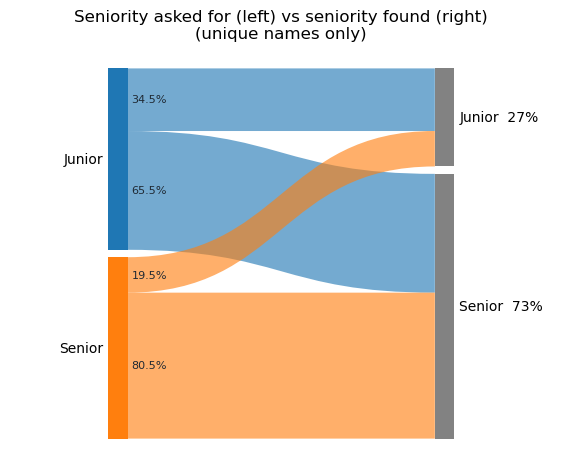

target  Junior  Senior
source                
Junior 34.5000 65.5000
Senior 19.5000 80.5000


In [39]:
df_sen = pd.read_csv(RESULTS / 'factualities/tables/seniority_flows.csv')

# Among homonyms the pick favours the asked seniority: restrict to `unique`
# for any claim about seniority.
print('Asked seniority == found seniority, by homonym-resolution view:')
tiebreak_report(df_sen, label='seniority_match')
print(f"\nPlotting the '{TIEBREAK_VIEW}' view.\n")
df_sen_view = tiebreak_view(df_sen)

flows = normalize_by_source(df_sen_view, value_col='n')
fig, ax = plot_sankey(
    flows,
    value_col='n',
    source_order=['Junior', 'Senior'],
    target_order=['Junior', 'Senior'],
    figsize=(7, 5),
    source_label_side='left',
    flow_fmt='{pct:.1f}%',
)
ax.set_title('Seniority asked for (left) vs seniority found (right)\n'
             f'({TIEBREAK_VIEW} names only)', fontsize=12, pad=16)
fig.savefig(PLOTS_DIR / 'plot_sankey_seniority.pdf', bbox_inches='tight')
plt.show()

# The numbers behind the ribbons, since a 2x2 Sankey is easy to misread.
pivot = (df_sen_view.groupby(['source', 'target'])['n'].sum().unstack(fill_value=0))
print((100 * pivot.div(pivot.sum(axis=1), axis=0)).round(1).to_string())

### Prompt country → perceived ethnicity

The only flow with 100% coverage, so nothing is hidden here. 5 prompt countries into 5
ethnicity categories (plus `Unknown`, which NamSor could not resolve).

`perceived_ethnicity` is inferred from the name, not self-reported — it says how the
*name* reads, which is the right object for a bias question but not a claim about the
person. Sources are normalised to 100% and each ribbon carries its share of the prompt
country.

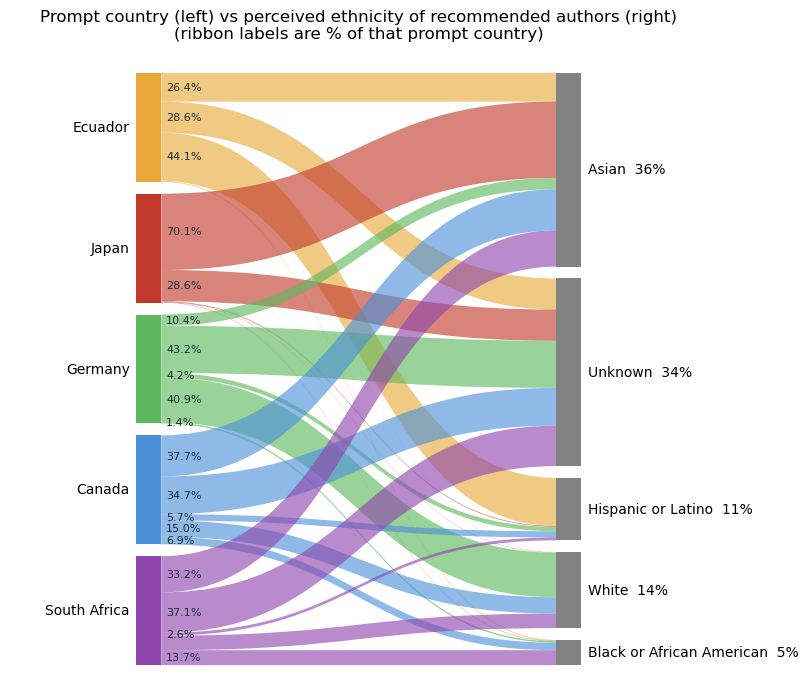

target   Asian  Unknown  Hispanic or Latino   White  Black or African American
source                                                                        
EC     26.4000  28.6000             44.1000  0.2000                     0.7000
JP     70.1000  28.6000              0.7000  0.3000                     0.4000
DE     10.4000  43.2000              4.2000 40.9000                     1.4000
CA     37.7000  34.7000              5.7000 15.0000                     6.9000
ZA     33.2000  37.1000              2.6000 13.3000                    13.7000


In [40]:
df_eth = pd.read_csv(RESULTS / 'factualities/tables/ethnicity_flows.csv')

flows = normalize_by_source(df_eth, value_col='n')
_eth_order = (df_eth.groupby('target')['n'].sum()
              .sort_values(ascending=False).index.tolist())
fig, ax = plot_sankey(
    flows,
    value_col='n',
    source_order=[i for i in LOCATION_ISO_ORDER if i in set(df_eth.source)],
    target_order=_eth_order,
    source_colors=_src_colors,
    source_labels=_src_labels,
    figsize=(9, 8),
    source_label_side='left',
    flow_fmt='{pct:.1f}%', flow_label_min_pct=1.0,
)
ax.set_title('Prompt country (left) vs perceived ethnicity of recommended authors (right)\n'
             '(ribbon labels are % of that prompt country)', fontsize=12, pad=16)
fig.savefig(PLOTS_DIR / 'plot_sankey_ethnicity.pdf', bbox_inches='tight')
plt.show()

_pct = (100 * df_eth.pivot_table(index='source', columns='target', values='n', aggfunc='sum')
        .fillna(0).pipe(lambda d: d.div(d.sum(axis=1), axis=0)))
print(_pct.reindex(index=[i for i in LOCATION_ISO_ORDER if i in _pct.index],
                   columns=_eth_order).round(1).to_string())

### Prompt field → ground-truth field

Same level of the taxonomy on both sides, so the diagonal is the whole story: ask for a
physicist, does the matched author actually publish in Physics? Off-diagonal mass is field
drift. Built from `field_flows.csv` (`source = field_en`, `target = gt_field`), coverage
65.0% — limited by `gt_field`, which only exists for authors matched in Semantic Scholar.

The columns are in the same order on both sides, so the diagonal runs straight across;
ribbon labels are the share *of the prompt field*, i.e. rows sum to 100%.

Prompt field == ground-truth field, by homonym-resolution view:
         recommendations  field_match_%
view                                   
unique            447622        30.1000
cascade          1481114        66.7000
all              1928736        58.2000

Plotting the 'unique' view.



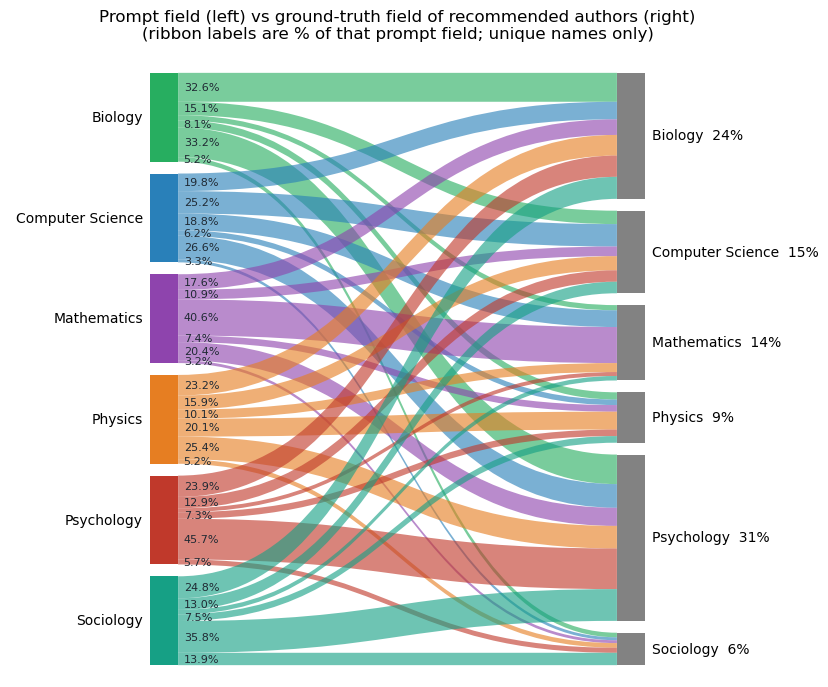

target            Biology  Computer Science  Mathematics  Physics  Psychology  Sociology
source                                                                                  
Biology           32.6000           15.1000       5.8000   8.1000     33.2000     5.2000
Computer Science  19.8000           25.2000      18.8000   6.2000     26.6000     3.3000
Mathematics       17.6000           10.9000      40.6000   7.4000     20.4000     3.2000
Physics           23.2000           15.9000      10.1000  20.1000     25.4000     5.2000
Psychology        23.9000           12.9000       4.5000   7.3000     45.7000     5.7000
Sociology         24.8000           13.0000       5.0000   7.5000     35.8000    13.9000

On-diagonal (asked field == found field): 29.7% on average across fields

Lift vs the reference population (1.0 = what a random name match gives)
target            Biology  Computer Science  Mathematics  Physics  Psychology  Sociology
source                                              

In [41]:
df_field = pd.read_csv(RESULTS / 'factualities/tables/field_flows.csv')

print('Prompt field == ground-truth field, by homonym-resolution view:')
tiebreak_report(df_field, label='field_match')
print(f"\nPlotting the '{TIEBREAK_VIEW}' view.\n")
df_view = tiebreak_view(df_field)

# Same six categories on both sides — identical order left and right so the
# diagonal (asked field == found field) reads as a straight band.
_forder = [f for f in FIELD_ORDER if f in set(df_view.source) | set(df_view.target)]

flows = normalize_by_source(df_view, value_col='n')
fig, ax = plot_sankey(
    flows,
    value_col='n',
    source_order=_forder,
    target_order=_forder,
    source_colors=FIELD_COLORS,
    figsize=(10, 8),
    source_label_side='left',
    flow_fmt='{pct:.1f}%', flow_label_min_pct=1.0,
)
ax.set_title('Prompt field (left) vs ground-truth field of recommended authors (right)\n'
             f'(ribbon labels are % of that prompt field; {TIEBREAK_VIEW} names only)',
             fontsize=12, pad=16)
fig.savefig(PLOTS_DIR / 'plot_sankey_field.pdf', bbox_inches='tight')
plt.show()

_pct = (100 * df_view.pivot_table(index='source', columns='target', values='n', aggfunc='sum')
        .fillna(0).pipe(lambda d: d.div(d.sum(axis=1), axis=0))).reindex(index=_forder, columns=_forder)
print(_pct.round(1).to_string())
print(f'\nOn-diagonal (asked field == found field): '
      f'{np.diag(_pct.values).mean():.1f}% on average across fields')

# ── Baseline ──────────────────────────────────────────────────────────────────
# The matcher searches a reference table that is 31% Biology and 5% Sociology,
# so "half of them land in Biology" is not drift on its own. `lift` is the
# observed share divided by that population share: 1.0 is exactly what matching
# a random name would produce, >1 means the field is over-returned.
_base = (pd.read_csv(RESULTS / 'factualities/tables/gt_field_baseline.csv')
         .set_index('field')['share'])
_lift = (_pct / _base.reindex(_pct.columns)).round(2)
print('\nLift vs the reference population (1.0 = what a random name match gives)')
print(_lift.to_string())

### Prompt subfield → ground-truth field

The cross-level view, kept separate on purpose: the ground truth has **no subfield**.
Semantic Scholar's researcher table carries only `Field` (Biology, Computer Science,
Mathematics, Physics, Psychology, Sociology), so "subfield vs subfield" cannot be drawn
from it — see the note in `build_sankey_flows.py`. What this figure asks instead is
whether a subfield lands in its *parent* field: ask for a number theorist, do you get a
mathematician?

Sources are grouped by parent field and coloured with it (`SUBFIELD_COLORS`), so the
expected flow is each subfield going to the target of its own colour. The manual check
below prints that number for every subfield.

Subfield flows, 'unique' view: 447,622 of 1,928,736 recommendations



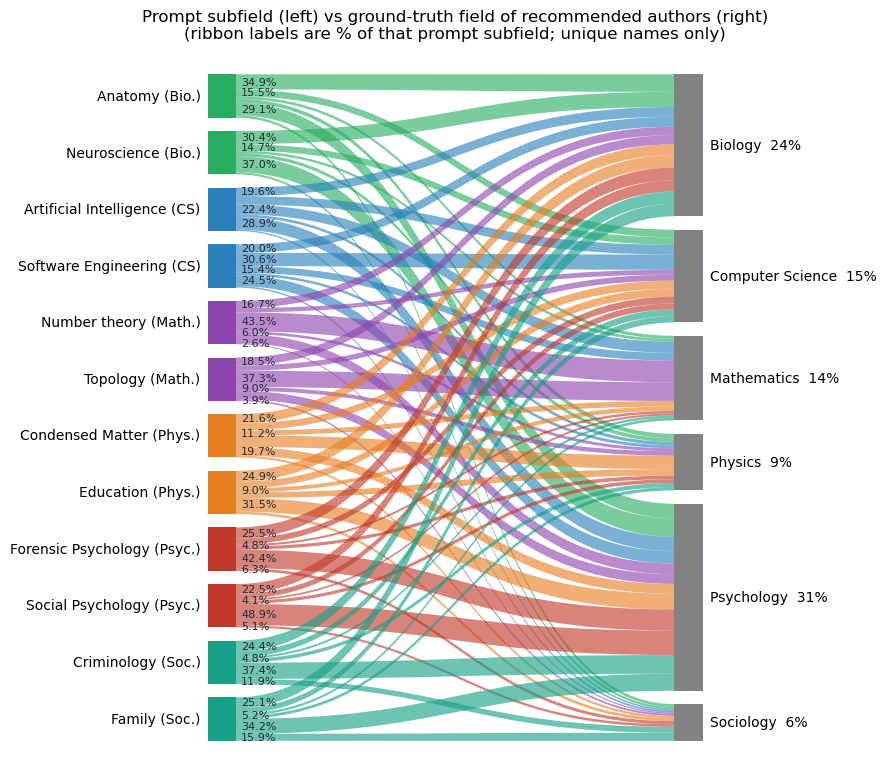

target                   Biology  Computer Science  Mathematics  Physics  Psychology  Sociology
source                                                                                         
Anatomy                  34.9000           15.5000       6.1000   8.8000     29.1000     5.6000
Neuroscience             30.4000           14.7000       5.6000   7.6000     37.0000     4.7000
Artificial Intelligence  19.6000           19.6000      22.4000   6.4000     28.9000     3.1000
Software Engineering     20.0000           30.6000      15.4000   6.0000     24.5000     3.5000
Number theory            16.7000            9.9000      43.5000   6.0000     21.3000     2.6000
Topology                 18.5000           12.0000      37.3000   9.0000     19.4000     3.9000
Condensed Matter         21.6000           16.1000      11.2000  26.8000     19.7000     4.6000
Education                24.9000           15.7000       9.0000  13.1000     31.5000     5.8000
Forensic Psychology      25.5000        

In [42]:
df_sub = pd.read_csv(RESULTS / 'factualities/tables/subfield_flows.csv')
df_sub_view = tiebreak_view(df_sub)
print(f"Subfield flows, '{TIEBREAK_VIEW}' view: {df_sub_view.n.sum():,} of "
      f"{df_sub.n.sum():,} recommendations\n")

# Parent field of each subfield, taken from the prompt itself (`field_en` is the
# field the subfield was asked under), not from a hand-written map.
_parent = df_sub_view.groupby('source')['field_en'].agg(lambda s: s.value_counts().idxmax())
_ambiguous = df_sub_view.groupby('source')['field_en'].nunique()
assert (_ambiguous == 1).all(), f'subfield with >1 parent field: {_ambiguous[_ambiguous > 1]}'

_forder = [f for f in FIELD_ORDER if f in set(df_sub_view.target)]
_sorder = sorted(_parent.index, key=lambda s: (_forder.index(_parent[s]), s))

# "Education" on its own is unreadable here — in this design it is *Physics*
# Education — so every subfield carries its parent field in the label.
_slabels = {s: f'{s} ({FIELD_MAP.get(_parent[s], _parent[s])})' for s in _sorder}

flows = normalize_by_source(df_sub_view, value_col='n')
fig, ax = plot_sankey(
    flows,
    value_col='n',
    source_order=_sorder,
    target_order=_forder,
    source_colors=SUBFIELD_COLORS,
    source_labels=_slabels,
    figsize=(10, 9),
    source_label_side='left',
    flow_fmt='{pct:.1f}%', flow_label_min_pct=1.0,
)
ax.set_title('Prompt subfield (left) vs ground-truth field of recommended authors (right)\n'
             f'(ribbon labels are % of that prompt subfield; {TIEBREAK_VIEW} names only)',
             fontsize=12, pad=16)
fig.savefig(PLOTS_DIR / 'plot_sankey_subfield.pdf', bbox_inches='tight')
plt.show()

# ── Manual check ──────────────────────────────────────────────────────────────
# Row = prompt subfield, column = found field, cell = % of that subfield.
_pct = (100 * df_sub_view.pivot_table(index='source', columns='target', values='n', aggfunc='sum')
        .fillna(0).pipe(lambda d: d.div(d.sum(axis=1), axis=0))).reindex(index=_sorder, columns=_forder)
_chk = pd.DataFrame({
    'parent_field': _parent.reindex(_sorder),
    'to_parent_%': [_pct.loc[s, _parent[s]] for s in _sorder],
    'top_field': _pct.idxmax(axis=1),
    'top_%': _pct.max(axis=1).round(1),
    'n': df_sub_view.groupby('source')['n'].sum().reindex(_sorder),
})
_chk['lands_in_parent'] = _chk.parent_field == _chk.top_field
print(_pct.round(1).to_string())
print()
print(_chk.round(1).to_string())
print(f'\nSubfields whose modal field is their own parent: '
      f'{_chk.lands_in_parent.sum()} / {len(_chk)}')
print(f'Rows sum to 100%: {bool(np.allclose(_pct.sum(axis=1), 100))}')

# ── Baseline ──────────────────────────────────────────────────────────────────
_base = (pd.read_csv(RESULTS / 'factualities/tables/gt_field_baseline.csv')
         .set_index('field')['share'])
_lift = (_pct / _base.reindex(_pct.columns)).round(2)
print('\nLift vs the reference population (1.0 = what a random name match gives)')
print(_lift.to_string())

### Prompt language → author country

Does asking in German return German-based authors even when the prompt names no country?
Only 3 sources, so the figure is narrow, but it isolates language from the country prompt
that the location Sankey above already covers.

Coverage 84.8%, limited by `oa_country_code`. The five prompted countries are pinned on
the right, as in the location figure, and the tail beyond the top 12 is folded into
`Other`. Ribbon labels are % of that language.

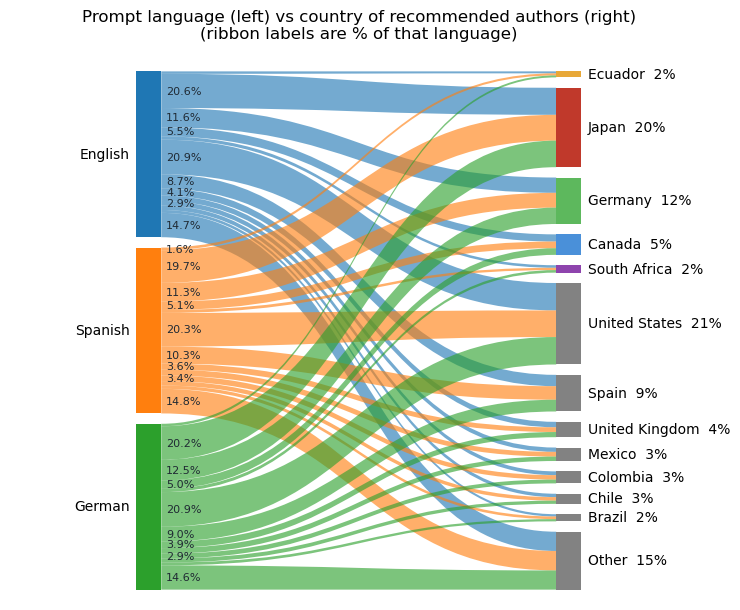

target      EC      JP      DE     CA     ZA      US      ES     GB     MX     CO     CL     BR   Other
source                                                                                                 
English 1.5000 20.6000 11.6000 5.5000 2.0000 20.9000  8.7000 4.1000 3.3000 2.9000 2.6000 1.8000 14.7000
Spanish 1.6000 19.7000 11.3000 5.1000 1.8000 20.3000 10.3000 3.6000 3.6000 3.4000 2.7000 2.0000 14.8000
German  1.5000 20.2000 12.5000 5.0000 1.9000 20.9000  9.0000 3.9000 3.4000 2.9000 2.4000 1.7000 14.6000


In [43]:
df_lang = pd.read_csv(RESULTS / 'factualities/tables/language_flows.csv')

# Ecuador pinned on the right for the same reason as in the location figure —
# otherwise it disappears into `Other` and the Spanish row cannot be read.
flows = collapse_tail(df_lang, target_col='target', value_col='n', top_n=12,
                      keep=LOCATION_ISO_ORDER)
flows = normalize_by_source(flows, value_col='n')

# Same country styling as the location figure: order, English names, colours.
_order, _dst_labels, _dst_colors = country_target_style(flows.target.unique())

fig, ax = plot_sankey(
    flows,
    value_col='n',
    source_order=['English', 'Spanish', 'German'],
    target_order=_order,
    target_labels=_dst_labels,
    target_colors=_dst_colors,
    figsize=(9, 7),
    source_label_side='left',
    flow_fmt='{pct:.1f}%', flow_label_min_pct=1.5,
)
ax.set_title('Prompt language (left) vs country of recommended authors (right)\n'
             '(ribbon labels are % of that language)', fontsize=12, pad=16)
fig.savefig(PLOTS_DIR / 'plot_sankey_language.pdf', bbox_inches='tight')
plt.show()

_pct = (100 * flows.pivot_table(index='source', columns='target', values='n', aggfunc='sum')
        .fillna(0)).reindex(index=['English', 'Spanish', 'German'], columns=_order)
print(_pct.round(1).to_string())

### Prompt country → gender of the recommended author

`gt_gender` is Semantic Scholar's Genderize+Namsor label for the matched author
(`Combined_gender`), so it exists only for authors found there — coverage 64.8%, and the
only two labels in the data are `male` and `female`. Read the ribbon labels as "of every
factual recommendation for a prompt naming <country>, this share are women".

Sources are normalised to 100%, so the five rows are comparable even though the countries
differ a lot in how many authors resolve at all.

1,919,701 recommendations | targets: ['female', 'male']


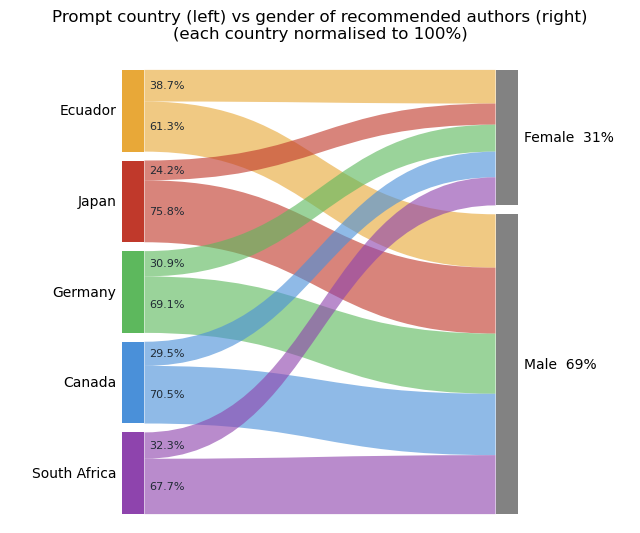

target        female    male
Ecuador      38.7000 61.3000
Japan        24.2000 75.8000
Germany      30.9000 69.1000
Canada       29.5000 70.5000
South Africa 32.3000 67.7000

Spread in the female share across prompt countries: 14.4 pp


In [44]:
df_gender = pd.read_csv(RESULTS / 'factualities/tables/gender_flows.csv')
print(f'{df_gender.n.sum():,} recommendations | targets: {sorted(df_gender.target.unique())}')

_gorder = [g for g in ['female', 'male'] if g in set(df_gender.target)]
flows = normalize_by_source(df_gender, value_col='n')
fig, ax = plot_sankey(
    flows,
    value_col='n',
    source_order=[i for i in LOCATION_ISO_ORDER if i in set(df_gender.source)],
    target_order=_gorder,
    source_colors=_src_colors,
    source_labels=_src_labels,
    target_labels={g: GENDER_MAP.get(g, g.title()) for g in _gorder},
    figsize=(8, 6), node_gap=0.02,
    source_label_side='left',
    flow_fmt='{pct:.1f}%',
)
ax.set_title('Prompt country (left) vs gender of recommended authors (right)\n'
             '(each country normalised to 100%)', fontsize=12, pad=16)
fig.savefig(PLOTS_DIR / 'plot_sankey_country_gender.pdf', bbox_inches='tight')
plt.show()

_pct = (100 * df_gender.pivot_table(index='source', columns='target', values='n', aggfunc='sum')
        .fillna(0).pipe(lambda d: d.div(d.sum(axis=1), axis=0)))
_pct = _pct.reindex(index=[i for i in LOCATION_ISO_ORDER if i in _pct.index], columns=_gorder)
_pct.index = [_src_labels.get(i, i) for i in _pct.index]
print(_pct.round(1).to_string())
print(f'\nSpread in the female share across prompt countries: '
      f'{_pct["female"].max() - _pct["female"].min():.1f} pp')